In [1]:
import obspy
from obspy import read
from geopy.distance import geodesic
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
from obspy.signal.filter import lowpass
from obspy.clients.fdsn.client import Client
import json
import scipy
import xarray as xr
from matplotlib.colors import LightSource
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
import matplotlib
from matplotlib import colors
from pyproj import Proj
from geopy.distance import geodesic
import pickle
import matplotlib.animation as animation
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 
from math import radians, cos, sin, atan2, sqrt, degrees
import imageio
from itertools import product
import dask
from dask.diagnostics import ProgressBar
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)

In [2]:
2100/3

700.0

## Which are the first stations that trigger for Tohoku?

- J0647, J0654, J0656, J0491, J0649
- ^ those are the ones in the first EPIC solution for the 100 Hz case

- The first EPIC solution when downsampling has WAY more stations:
- J0654, J1434, J0648, J1426, J1322, 

## Let's start by looking at J0654

In [3]:
mseed_path = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KN.J0654.HLZ.mseed'
mseed_gain = 1577.23494898

st = read(mseed_path)

trace_index = 0
tr = st[trace_index]
fs = float(tr.stats.sampling_rate)
dt = 1.0 / fs

raw = tr.data.astype(np.float64)
channel = str(tr.stats.channel)

In [4]:
p = EWP2Params()
tg = process_toground(raw, dt, channel, mseed_gain, p)
pk = process_picker(tg["v"], dt, p)

NameError: name 'EWP2Params' is not defined

In [ ]:
snr = np.divide(tg["s"], tg["n"], out=np.zeros_like(tg["s"]), where=tg["n"] != 0.0)
tsec = np.arange(len(raw), dtype=np.float64) * dt
stalta = pk["ratio"]
filtered = pk["r_picker"]

In [ ]:
%matplotlib widget
fig,ax = plt.subplots(4)
ax[0].plot(tsec,raw)
ax[1].plot(tsec,filtered)
ax[2].plot(tsec,snr)
ax[3].plot(tsec,stalta)

# Info from first trigger:
20:22:01:135| INFO | N:H: sta chan net loc      lat       lon                    time up c  rsp  tsp            tp         tpsnr  dsp            pd         pdsnr  vsp            pv         pvsnr  asp            pa         pasnr    assoc tel tsec plen    sps toffset arrtime protime fndtime quetime sndtime  e2time buftime zc ne_to_z  acc_range


20:22:03:089| INFO | N: J0654  HLZ  KN  --  38.5769  141.4514 2026-08-20T20:22:02.860  0 Z    6    0  0.000000e+00  0.000000e+00    0  9.858536e-05  2.149358e-03    5 -2.335288e-03  2.143897e-03    2 -3.244113e-02  1.950128e-03  WAITING   0  0.0  100  100.0  0.9300  0.2267  0.2270  0.2275  0.2284  0.2286  0.0027  0.0027 22    0.00  0.000e+00

In [ ]:
#!/usr/bin/env python3
"""
Plot ELARM-SWP2-style processing products from a MiniSEED file.

Outputs:
1) raw data
2) filtered data used by picker (high-pass r) plus velocity v
3) STA/LTA ratio time series
4) SNR time series (s/n from ToGround signal/noise channels)

Extras:
- trigger generation using PickerTSPModule logic
- per-trigger quality-check report showing pass criteria used by the picker

This script mirrors equations in:
- ToGroundTSPModule.cpp
- PickerTSPModule.cpp
and uses defaults from EWP2 params unless overridden by a params file.
"""

from __future__ import annotations

import argparse
import math
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
from obspy import read


# -----------------------------
# Parameter handling
# -----------------------------

DEFAULT_PARAMS: Dict[str, float | int | bool] = {
    # ToGround
    "HPFCAcceleration": 0.994,
    "HPFCVelocityA": 0.994,
    "HPFCVelocityV": 0.994,
    "HPFCDisplacement": 0.994,
    "TSCTauP": 1.0,
    "HPFCRaw": 0.994,
    "TSCTSignal": 0.05,
    "RICTauK": 3.0,
    "TSCTNoise": 30.0,
    # Picker
    "TSCTsta": 0.05,
    "TSCTlta": 5.0,
    "TrigLev": 20.0,
    "TrigDur": 10,
    "UseTrigStab": False,
    "TrigStabLev": 12.0,
    "UseTrigGapDelay": True,
    "TrigGapDur": 5,
}


def _parse_value(text: str):
    t = text.strip()
    if t.lower() in {"true", "false"}:
        return t.lower() == "true"
    try:
        if any(c in t.lower() for c in [".", "e"]):
            return float(t)
        return int(t)
    except ValueError:
        return t


def load_params(path: Optional[Path]) -> Dict[str, float | int | bool]:
    params = dict(DEFAULT_PARAMS)
    if path is None:
        return params

    with path.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            if "#" in line:
                line = line.split("#", 1)[0].strip()
            if not line:
                continue
            parts = line.split()
            if len(parts) < 2:
                continue
            key = parts[0]
            val = _parse_value(parts[1])
            params[key] = val

    return params


# -----------------------------
# ToGround implementation
# -----------------------------


@dataclass
class ToGroundState:
    was_gap: bool = True
    var_z0: float = 0.0
    var_a0: float = 0.0
    var_v0: float = 0.0
    var_d0: float = 0.0
    var_v1minus: float = 0.0
    var_vlp1minus: float = 0.0
    var_vlp0: float = 0.0
    var_sigma0: float = 0.0
    var_y0: float = 0.0
    var_r0: float = 0.0
    var_s0: float = 0.0
    var_n0: float = 0.0


class ToGroundProcessor:
    def __init__(self, channel_code: str, samplerate: float, gain: float, p: Dict):
        self.channel_code = channel_code
        self.samplerate = samplerate
        self.delta_t = 1.0 / samplerate
        self.gain = gain if gain != 0 else 1e-10

        # waveform type from channel[1] in C++
        c1 = channel_code[1] if len(channel_code) > 1 else "H"
        self.acceleration_input = c1 in {"N", "L"}

        self.q_acc = float(p["HPFCAcceleration"])
        self.q_vel_a = float(p["HPFCVelocityA"])
        self.q_vel_v = float(p["HPFCVelocityV"])
        self.q_disp = float(p["HPFCDisplacement"])
        self.lambda_taup = float(p["TSCTauP"])
        self.q_snr = float(p["HPFCRaw"])
        self.t_signal = float(p["TSCTSignal"])
        self.tau_k = float(p["RICTauK"])
        self.t_noise = float(p["TSCTNoise"])

        self.bg_for_accel = 2.0 * self.gain / (1.0 + self.q_acc)
        self.tg_for_accel = self.delta_t * self.gain
        self.t2b_for_velo = (1.0 + self.q_vel_a) * self.delta_t / 4.0
        self.bg_for_velo = 2.0 * self.gain / (1.0 + self.q_vel_v)
        self.t2b_for_disp = (1.0 + self.q_disp) * self.delta_t / 4.0

        self.alpha = (self.lambda_taup - self.delta_t) / self.lambda_taup
        self.alpha_signal = (self.t_signal - self.delta_t) / self.t_signal
        self.alpha_noise = (self.t_noise - self.delta_t) / self.t_noise

        # low-pass coeffs for vlp
        f_L = 1.8
        f = math.pi * f_L * self.delta_t
        fau = (1.0 / math.tan(f)) * (1.0 / math.tan(3.0 * f))
        self.gain_lp = 1.0 / (1.0 + math.sqrt(abs(2.0 * fau)) + fau)
        self.h1 = 2.0
        self.h2 = 1.0
        self.h3 = 2.0 * (1.0 - fau) * self.gain_lp
        self.h4 = 2.0 * (1.0 + fau) * self.gain_lp - 1.0

        self.state = ToGroundState()

    def restart(self):
        self.state = ToGroundState()

    def process(self, raw: np.ndarray) -> Dict[str, np.ndarray]:
        raw = raw.astype(np.float64, copy=False)
        n = raw.size
        out = {
            "raw": raw.copy(),
            "a": np.zeros(n, dtype=np.float64),
            "v": np.zeros(n, dtype=np.float64),
            "d": np.zeros(n, dtype=np.float64),
            "t": np.zeros(n, dtype=np.float64),
            "s": np.zeros(n, dtype=np.float64),
            "n": np.zeros(n, dtype=np.float64),
            "r": np.zeros(n, dtype=np.float64),
        }

        if n == 0:
            return out

        st = self.state

        if st.was_gap:
            st.was_gap = False
            st.var_z0 = raw[0]

        # workspace
        vlp = np.zeros(n, dtype=np.float64)
        sigma = np.zeros(n, dtype=np.float64)
        y = np.zeros(n, dtype=np.float64)
        r = np.zeros(n, dtype=np.float64)

        # i = 0
        if self.acceleration_input:
            out["a"][0] = (raw[0] - st.var_z0) / self.bg_for_accel + self.q_acc * st.var_a0
            out["v"][0] = (out["a"][0] + st.var_a0) * self.t2b_for_velo + self.q_vel_a * st.var_v0
        else:
            out["a"][0] = (raw[0] - st.var_z0) / self.tg_for_accel
            out["v"][0] = (raw[0] - st.var_z0) / self.bg_for_velo + self.q_vel_v * st.var_v0

        out["d"][0] = (out["v"][0] + st.var_v0) * self.t2b_for_disp + self.q_disp * st.var_d0

        vlp[0] = (
            self.gain_lp * (out["v"][0] + self.h1 * st.var_v0 + self.h2 * st.var_v1minus)
            - self.h3 * st.var_vlp0
            - self.h4 * st.var_vlp1minus
        )
        sigma[0] = self.alpha * st.var_sigma0 + ((vlp[0] - st.var_vlp0) / self.delta_t) ** 2
        y[0] = self.alpha * st.var_y0 + vlp[0] ** 2

        lower = (0.01 / (2.0 * math.pi)) ** 2 * sigma[0]
        upper = (100.0 / (2.0 * math.pi)) ** 2 * sigma[0]
        if y[0] > lower and y[0] < upper:
            out["t"][0] = 0.0 if sigma[0] == 0.0 else 2.0 * math.pi * math.sqrt(abs(y[0] / sigma[0]))

        r[0] = self.q_snr * st.var_r0 + raw[0] - st.var_z0
        cf0 = r[0] ** 2 + self.tau_k * (raw[0] - st.var_z0) ** 2
        out["s"][0] = self.alpha_signal * st.var_s0 + (1.0 - self.alpha_signal) * cf0
        out["n"][0] = self.alpha_noise * st.var_n0 + (1.0 - self.alpha_noise) * cf0

        # i >= 1
        for i in range(1, n):
            dz = raw[i] - raw[i - 1]
            if self.acceleration_input:
                out["a"][i] = dz / self.bg_for_accel + self.q_acc * out["a"][i - 1]
                out["v"][i] = (out["a"][i] + out["a"][i - 1]) * self.t2b_for_velo + self.q_vel_a * out["v"][i - 1]
            else:
                out["a"][i] = dz / self.tg_for_accel
                out["v"][i] = dz / self.bg_for_velo + self.q_vel_v * out["v"][i - 1]

            out["d"][i] = (out["v"][i] + out["v"][i - 1]) * self.t2b_for_disp + self.q_disp * out["d"][i - 1]

            if i == 1:
                vlp[i] = (
                    self.gain_lp * (out["v"][i] + self.h1 * out["v"][i - 1] + self.h2 * st.var_v0)
                    - self.h3 * vlp[i - 1]
                    - self.h4 * st.var_vlp0
                )
            else:
                vlp[i] = (
                    self.gain_lp * (out["v"][i] + self.h1 * out["v"][i - 1] + self.h2 * out["v"][i - 2])
                    - self.h3 * vlp[i - 1]
                    - self.h4 * vlp[i - 2]
                )

            sigma[i] = self.alpha * sigma[i - 1] + ((vlp[i] - vlp[i - 1]) / self.delta_t) ** 2
            y[i] = self.alpha * y[i - 1] + vlp[i] ** 2

            lower = (0.01 / (2.0 * math.pi)) ** 2 * sigma[i]
            upper = (100.0 / (2.0 * math.pi)) ** 2 * sigma[i]
            if y[i] > lower and y[i] < upper:
                out["t"][i] = 0.0 if sigma[i] == 0.0 else 2.0 * math.pi * math.sqrt(abs(y[i] / sigma[i]))
            else:
                out["t"][i] = 0.0

            r[i] = self.q_snr * r[i - 1] + dz
            cf = r[i] ** 2 + self.tau_k * dz**2
            out["s"][i] = self.alpha_signal * out["s"][i - 1] + (1.0 - self.alpha_signal) * cf
            out["n"][i] = self.alpha_noise * out["n"][i - 1] + (1.0 - self.alpha_noise) * cf

        st.var_z0 = raw[-1]
        st.var_a0 = out["a"][-1]
        st.var_v0 = out["v"][-1]
        st.var_d0 = out["d"][-1]
        st.var_vlp0 = vlp[-1]
        if n > 2:
            st.var_v1minus = out["v"][-2]
            st.var_vlp1minus = vlp[-2]
        else:
            st.var_v1minus = 0.0
            st.var_vlp1minus = 0.0
        st.var_sigma0 = sigma[-1]
        st.var_y0 = y[-1]
        st.var_r0 = r[-1]
        st.var_s0 = out["s"][-1]
        st.var_n0 = out["n"][-1]

        return out


# -----------------------------
# Picker implementation + trigger quality checks
# -----------------------------


@dataclass
class PickerState:
    prev_r: float = 0.0
    prev_v: float = 0.0
    prev_sta: float = 0.0
    prev_lta: float = 0.0
    stabilized: bool = False
    in_gap: bool = True
    time_untrig: float = 0.0
    time_gap_delay: float = 0.0


@dataclass
class TriggerEvent:
    sample_index: int
    sample_time_epoch: float
    sta: float
    lta: float
    ratio: float
    trig_level: float
    trig_stab_level: float
    stabilized: bool
    passed_stab_check: bool
    passed_gap_delay_check: bool
    passed_untrig_check: bool
    passed_ratio_check: bool
    gap_delay_until_epoch: float
    untrig_until_epoch: float
    r_picker: float
    passed_all_checks: bool


class PickerProcessor:
    def __init__(self, params: Dict):
        self.q_raw = float(params["HPFCRaw"])
        self.t_sta = max(float(params["TSCTsta"]), 1e-10)
        self.t_lta = max(float(params["TSCTlta"]), 1e-10)
        self.tau_k = float(params["RICTauK"])
        self.trig_lev = float(params["TrigLev"])
        self.trig_dur = int(params["TrigDur"])
        self.use_trig_stab = bool(params["UseTrigStab"])
        self.trig_stab_lev = float(params["TrigStabLev"])
        self.use_trig_gap_delay = bool(params["UseTrigGapDelay"])
        self.trig_gap_dur = int(params["TrigGapDur"])

        self.state = PickerState(stabilized=(False if self.use_trig_stab else True))

    def restart(self, sample_time: float):
        _ = sample_time
        self.state.prev_r = 0.0
        self.state.prev_v = 0.0
        self.state.prev_sta = 0.0
        self.state.prev_lta = 0.0
        self.state.in_gap = True
        if self.use_trig_stab:
            self.state.stabilized = False

    def _evaluate_checks(self, sample_time: float, sta_i: float, lta_i: float, stabilized: bool) -> Dict[str, bool | float]:
        ratio = (sta_i / lta_i) if lta_i != 0.0 else 0.0
        passed_ratio_check = sta_i > self.trig_lev * lta_i
        passed_stab_check = stabilized
        passed_gap_delay_check = (sample_time > self.state.time_gap_delay) if self.use_trig_gap_delay else True
        passed_untrig_check = sample_time > self.state.time_untrig

        passed_all = passed_ratio_check and passed_stab_check and passed_gap_delay_check and passed_untrig_check
        return {
            "ratio": ratio,
            "passed_ratio_check": passed_ratio_check,
            "passed_stab_check": passed_stab_check,
            "passed_gap_delay_check": passed_gap_delay_check,
            "passed_untrig_check": passed_untrig_check,
            "passed_all_checks": passed_all,
        }

    def process(self, v: np.ndarray, first_sample_time: float, samplerate: float) -> Dict[str, np.ndarray | List[TriggerEvent]]:
        n = len(v)
        r = np.zeros(n, dtype=np.float64)
        sta = np.zeros(n, dtype=np.float64)
        lta = np.zeros(n, dtype=np.float64)
        trigger_events: List[TriggerEvent] = []

        if n == 0:
            return {
                "r_picker": r,
                "sta": sta,
                "lta": lta,
                "ratio": np.zeros(0, dtype=np.float64),
                "trigger_events": trigger_events,
            }

        st = self.state
        if st.in_gap:
            st.in_gap = False
            st.time_gap_delay = first_sample_time + abs(float(self.trig_gap_dur))

        delta_t = 1.0 / samplerate
        alpha_1_sta = delta_t / self.t_sta
        alpha_1_lta = delta_t / self.t_lta
        alpha_sta = 1.0 - alpha_1_sta
        alpha_lta = 1.0 - alpha_1_lta

        r[0] = self.q_raw * st.prev_r + (v[0] - st.prev_v)
        cf0 = r[0] ** 2 + self.tau_k * (v[0] - st.prev_v) ** 2
        sta[0] = alpha_sta * st.prev_sta + alpha_1_sta * cf0
        lta[0] = alpha_lta * st.prev_lta + alpha_1_lta * cf0

        if sta[0] < self.trig_stab_lev * lta[0]:
            st.stabilized = True

        checks0 = self._evaluate_checks(first_sample_time, float(sta[0]), float(lta[0]), st.stabilized)
        if bool(checks0["passed_all_checks"]):
            trigger_events.append(
                TriggerEvent(
                    sample_index=0,
                    sample_time_epoch=first_sample_time,
                    sta=float(sta[0]),
                    lta=float(lta[0]),
                    ratio=float(checks0["ratio"]),
                    trig_level=self.trig_lev,
                    trig_stab_level=self.trig_stab_lev,
                    stabilized=st.stabilized,
                    passed_stab_check=bool(checks0["passed_stab_check"]),
                    passed_gap_delay_check=bool(checks0["passed_gap_delay_check"]),
                    passed_untrig_check=bool(checks0["passed_untrig_check"]),
                    passed_ratio_check=bool(checks0["passed_ratio_check"]),
                    gap_delay_until_epoch=st.time_gap_delay,
                    untrig_until_epoch=st.time_untrig,
                    r_picker=float(r[0]),
                    passed_all_checks=True,
                )
            )
            st.time_untrig = first_sample_time + self.trig_dur

        for i in range(1, n):
            sample_time = first_sample_time + i * delta_t
            r[i] = self.q_raw * r[i - 1] + (v[i] - v[i - 1])
            cfi = r[i] ** 2 + self.tau_k * (v[i] - v[i - 1]) ** 2
            sta[i] = alpha_sta * sta[i - 1] + alpha_1_sta * cfi
            lta[i] = alpha_lta * lta[i - 1] + alpha_1_lta * cfi

            if sta[i] < self.trig_stab_lev * lta[i]:
                st.stabilized = True

            checks = self._evaluate_checks(sample_time, float(sta[i]), float(lta[i]), st.stabilized)
            if bool(checks["passed_all_checks"]):
                trigger_events.append(
                    TriggerEvent(
                        sample_index=i,
                        sample_time_epoch=sample_time,
                        sta=float(sta[i]),
                        lta=float(lta[i]),
                        ratio=float(checks["ratio"]),
                        trig_level=self.trig_lev,
                        trig_stab_level=self.trig_stab_lev,
                        stabilized=st.stabilized,
                        passed_stab_check=bool(checks["passed_stab_check"]),
                        passed_gap_delay_check=bool(checks["passed_gap_delay_check"]),
                        passed_untrig_check=bool(checks["passed_untrig_check"]),
                        passed_ratio_check=bool(checks["passed_ratio_check"]),
                        gap_delay_until_epoch=st.time_gap_delay,
                        untrig_until_epoch=st.time_untrig,
                        r_picker=float(r[i]),
                        passed_all_checks=True,
                    )
                )
                st.time_untrig = sample_time + self.trig_dur

        st.prev_v = float(v[-1])
        st.prev_r = float(r[-1])
        st.prev_sta = float(sta[-1])
        st.prev_lta = float(lta[-1])

        ratio = np.divide(sta, lta, out=np.zeros_like(sta), where=lta != 0.0)
        return {
            "r_picker": r,
            "sta": sta,
            "lta": lta,
            "ratio": ratio,
            "trigger_events": trigger_events,
        }


# -----------------------------
# Helpers
# -----------------------------


def _channel_triplet(stream, channel: Optional[str]):
    if channel:
        sel = stream.select(channel=channel)
        if len(sel) == 0:
            raise ValueError(f"No traces matched channel={channel}")
        ref = max(sel, key=lambda tr: tr.stats.npts)
    else:
        z_traces = [tr for tr in stream if str(tr.stats.channel).upper().endswith("Z")]
        ref = max(z_traces, key=lambda tr: tr.stats.npts) if z_traces else max(stream, key=lambda tr: tr.stats.npts)

    nsl = (ref.stats.network, ref.stats.station, ref.stats.location)
    chan = str(ref.stats.channel)
    if len(chan) < 1:
        raise ValueError("Invalid channel code on reference trace")

    prefix = chan[:-1] if len(chan) > 1 else chan
    zchan = prefix + "Z"
    nchan = prefix + "N"
    echan = prefix + "E"

    zst = stream.select(network=nsl[0], station=nsl[1], location=nsl[2], channel=zchan)
    if len(zst) == 0:
        zst = stream.select(network=nsl[0], station=nsl[1], location=nsl[2], channel=chan)

    nst = stream.select(network=nsl[0], station=nsl[1], location=nsl[2], channel=nchan)
    est = stream.select(network=nsl[0], station=nsl[1], location=nsl[2], channel=echan)

    # Fall back to any N/E ending channels on same NSL if exact prefix match not present.
    if len(nst) == 0:
        nst = stream.select(network=nsl[0], station=nsl[1], location=nsl[2], channel="*N")
    if len(est) == 0:
        est = stream.select(network=nsl[0], station=nsl[1], location=nsl[2], channel="*E")

    zst.sort(keys=["starttime"])
    nst.sort(keys=["starttime"])
    est.sort(keys=["starttime"])
    return zst, nst, est


def _process_component(stream_comp, params: Dict, gain_override: Optional[float], run_picker: bool):
    if len(stream_comp) == 0:
        return None

    ref = stream_comp[0]
    sr = float(ref.stats.sampling_rate)
    ch = str(ref.stats.channel)
    gain = gain_override if gain_override is not None else float(getattr(ref.stats, "calib", 1.0) or 1.0)

    tg = ToGroundProcessor(channel_code=ch, samplerate=sr, gain=gain, p=params)
    picker = PickerProcessor(params) if run_picker else None

    t_all: List[np.ndarray] = []
    raw_all: List[np.ndarray] = []
    a_all: List[np.ndarray] = []
    v_all: List[np.ndarray] = []
    d_all: List[np.ndarray] = []
    taup_all: List[np.ndarray] = []
    s_all: List[np.ndarray] = []
    n_all: List[np.ndarray] = []
    r_tg_all: List[np.ndarray] = []
    r_picker_all: List[np.ndarray] = []
    sta_all: List[np.ndarray] = []
    lta_all: List[np.ndarray] = []
    ratio_all: List[np.ndarray] = []
    trigger_events_all: List[TriggerEvent] = []

    prev_end: Optional[float] = None
    global_index_offset = 0

    for tr in stream_comp:
        tr_sr = float(tr.stats.sampling_rate)
        if abs(tr_sr - sr) > 1e-6:
            raise ValueError("All traces in one component must have same sample rate")

        seg_start = tr.stats.starttime.timestamp
        dt = 1.0 / sr
        if prev_end is not None and seg_start - prev_end > 1.5 * dt:
            tg.restart()
            if picker is not None:
                picker.restart(seg_start)

        raw = np.asarray(tr.data, dtype=np.float64)
        proc = tg.process(raw)
        npts = raw.size
        t = seg_start + np.arange(npts) * dt

        t_all.append(t)
        raw_all.append(proc["raw"])
        a_all.append(proc["a"])
        v_all.append(proc["v"])
        d_all.append(proc["d"])
        taup_all.append(proc["t"])
        s_all.append(proc["s"])
        n_all.append(proc["n"])
        r_tg_all.append(proc["r"])

        if picker is not None:
            pick = picker.process(proc["v"], seg_start, sr)
            r_picker_all.append(pick["r_picker"])
            sta_all.append(pick["sta"])
            lta_all.append(pick["lta"])
            ratio_all.append(pick["ratio"])

            for ev in pick["trigger_events"]:
                ev.sample_index += global_index_offset
                trigger_events_all.append(ev)
        else:
            r_picker_all.append(np.zeros_like(proc["v"]))
            sta_all.append(np.zeros_like(proc["v"]))
            lta_all.append(np.zeros_like(proc["v"]))
            ratio_all.append(np.zeros_like(proc["v"]))

        prev_end = seg_start + (npts - 1) * dt if npts > 0 else seg_start
        global_index_offset += npts

    t = np.concatenate(t_all) if t_all else np.zeros(0)
    raw = np.concatenate(raw_all) if raw_all else np.zeros(0)
    a = np.concatenate(a_all) if a_all else np.zeros(0)
    v = np.concatenate(v_all) if v_all else np.zeros(0)
    d = np.concatenate(d_all) if d_all else np.zeros(0)
    taup = np.concatenate(taup_all) if taup_all else np.zeros(0)
    s = np.concatenate(s_all) if s_all else np.zeros(0)
    n = np.concatenate(n_all) if n_all else np.zeros(0)
    r_tg = np.concatenate(r_tg_all) if r_tg_all else np.zeros(0)
    r_picker = np.concatenate(r_picker_all) if r_picker_all else np.zeros(0)
    sta = np.concatenate(sta_all) if sta_all else np.zeros(0)
    lta = np.concatenate(lta_all) if lta_all else np.zeros(0)
    ratio = np.concatenate(ratio_all) if ratio_all else np.zeros(0)
    snr = np.divide(s, n, out=np.zeros_like(s), where=n != 0.0) if s.size else np.zeros(0)

    return {
        "id": ref.id,
        "sr": sr,
        "channel": ch,
        "t": t,
        "raw": raw,
        "a": a,
        "v": v,
        "d": d,
        "taup": taup,
        "s": s,
        "n": n,
        "r_tg": r_tg,
        "r_picker": r_picker,
        "sta": sta,
        "lta": lta,
        "ratio": ratio,
        "snr": snr,
        "trigger_events": trigger_events_all,
        "start_epoch": ref.stats.starttime.timestamp,
    }


@dataclass
class TriggerMeasurements:
    sample_index: int
    time_epoch: float
    time_rel_s: float
    tsp: int
    tp: float
    tpsnr: float
    dsp: int
    pd: float
    pdsnr: float
    vsp: int
    pv: float
    pvsnr: float
    asp: int
    pa: float
    pasnr: float
    ne_to_z: float
    zc: int
    zc_vel: int
    zc_acc: int
    passed_ratio_check: int
    passed_stab_check: int
    passed_gap_delay_check: int
    passed_untrig_check: int
    passed_all_checks: int


def _compute_maxamp_metrics(z: Dict, trig_idx: int, params: Dict):
    t = z["t"]
    a = z["a"]
    v = z["v"]
    d = z["d"]
    taup = z["taup"]
    s = z["s"]
    n = z["n"]
    sr = float(z["sr"])

    half_dt = 0.5 / sr
    trigger_time = t[trig_idx]
    end_lag = float(params.get("MaxAmpEndLag", 4.0))
    taup_output_delay = float(params.get("TaupOutputDelay", 0.5))
    clip_level = float(params.get("ClipLevel", 6.0e12))
    clip_duration = float(params.get("ClipDuration", 0.5))

    pa = pv = pd = tp = 0.0
    asp = vsp = dsp = tsp = 0
    pasnr = pvsnr = pdsnr = tpsnr = -1.0

    noise = n[trig_idx] if 0 <= trig_idx < n.size else 0.0
    time_unclip = 0.0
    snr_i = -1.0

    i = trig_idx
    while i < t.size:
        sample_time = t[i]
        if sample_time > trigger_time + end_lag + half_dt:
            break

        if abs(sample_time - trigger_time) < half_dt:
            noise = n[i]

        if time_unclip > 0.0:
            if sample_time > time_unclip:
                if abs(s[i]) > clip_level:
                    time_unclip += clip_duration
                    snr_i = -1.0
                else:
                    time_unclip = 0.0
                    snr_i = 0.0 if noise == 0.0 else s[i] / noise
            else:
                snr_i = -1.0
        else:
            if abs(s[i]) > clip_level:
                time_unclip = sample_time + clip_duration
                snr_i = -1.0
            else:
                time_unclip = 0.0
                snr_i = 0.0 if noise == 0.0 else s[i] / noise

        off = int((sample_time - trigger_time) * sr + 0.5)

        if abs(pa) < abs(a[i]):
            pa = float(a[i])
            pasnr = float(snr_i)
            asp = off

        if abs(pv) < abs(v[i]):
            pv = float(v[i])
            pvsnr = float(snr_i)
            vsp = off

        if abs(pd) < abs(d[i]):
            pd = float(d[i])
            pdsnr = float(snr_i)
            dsp = off

        if sample_time - trigger_time > taup_output_delay and tp < taup[i]:
            tp = float(taup[i])
            tpsnr = float(snr_i)
            tsp = off

        i += 1

    return {
        "tsp": tsp,
        "tp": tp,
        "tpsnr": tpsnr,
        "dsp": dsp,
        "pd": pd,
        "pdsnr": pdsnr,
        "vsp": vsp,
        "pv": pv,
        "pvsnr": pvsnr,
        "asp": asp,
        "pa": pa,
        "pasnr": pasnr,
    }


def _window_values(t: np.ndarray, x: np.ndarray, tmin: float, tmax: float) -> np.ndarray:
    if t.size == 0 or x.size == 0:
        return np.zeros(0, dtype=float)
    m = (t > tmin) & (t < tmax)
    return x[m]


def _compute_ne_to_z(z: Dict, n_comp: Optional[Dict], e_comp: Optional[Dict], trigger_time: float, params: Dict):
    if n_comp is None or e_comp is None:
        return float("nan")

    sr = float(z["sr"])
    half_dt = 0.5 / sr
    start_lag = float(params.get("StartNEtoZ", 0.0))
    end_lag = float(params.get("EndNEtoZ", 0.05))
    tmin = trigger_time + start_lag - half_dt
    tmax = trigger_time + end_lag + half_dt

    zv = _window_values(z["t"], z["v"], tmin, tmax)
    nv = _window_values(n_comp["t"], n_comp["v"], tmin, tmax)
    ev = _window_values(e_comp["t"], e_comp["v"], tmin, tmax)

    if zv.size == 0 or nv.size == 0 or ev.size == 0:
        return float("nan")

    n_range = float(np.max(nv) - np.min(nv))
    e_range = float(np.max(ev) - np.min(ev))
    z_range = float(np.max(zv) - np.min(zv))

    if z_range == 0.0:
        return 0.0
    return max(n_range, e_range) / z_range


def _compute_zero_crossings(z: Dict, trigger_time: float, params: Dict):
    t = z["t"]
    v = z["v"]
    a = z["a"]
    if t.size == 0:
        return -1, -1, -1

    sr = float(z["sr"])
    half_dt = 0.5 / sr
    demean = bool(params.get("ZCrossDemean", True))
    demean_lead = float(params.get("ZCrossDemeanLead", 4.0))
    lead = float(params.get("ZCrossLead", 2.0))
    lag = float(params.get("ZCrossLag", 0.2))

    mean_start = trigger_time - demean_lead - half_dt
    cnt_start = trigger_time - lead - half_dt
    cnt_end = trigger_time + lag + half_dt

    mean_vel = 0.0
    mean_acc = 0.0
    if demean:
        mm = t > mean_start
        if np.any(mm):
            mean_vel = float(np.mean(v[mm]))
            mean_acc = float(np.mean(a[mm]))

    m = (t > cnt_start) & (t < cnt_end)
    if not np.any(m):
        return -1, -1, -1

    vv = v[m]
    zero_cross_vel = -1
    zero_cross_acc = -1
    crossing_greater_vel = False
    crossing_greater_acc = False

    for val in vv:
        if zero_cross_vel < 0:
            zero_cross_vel = 0
            crossing_greater_vel = val > mean_vel
        else:
            curr = val > mean_vel
            if curr != crossing_greater_vel:
                crossing_greater_vel = curr
                zero_cross_vel += 1

        # NOTE: source code compares zdata.v to mean_acc here (not zdata.a).
        if zero_cross_acc < 0:
            zero_cross_acc = 0
            crossing_greater_acc = val > mean_acc
        else:
            curr = val > mean_acc
            if curr != crossing_greater_acc:
                crossing_greater_acc = curr
                zero_cross_acc += 1

    if zero_cross_vel < 0 and zero_cross_acc < 0:
        zc = -1
    elif zero_cross_vel < 0:
        zc = zero_cross_acc
    elif zero_cross_acc < 0:
        zc = zero_cross_vel
    else:
        zc = min(zero_cross_vel, zero_cross_acc)

    return int(zc), int(zero_cross_vel), int(zero_cross_acc)


def build_trigger_measurements(
    trigger_events: List[TriggerEvent],
    z_proc: Dict,
    n_proc: Optional[Dict],
    e_proc: Optional[Dict],
    params: Dict,
) -> List[TriggerMeasurements]:
    rows: List[TriggerMeasurements] = []
    if not trigger_events:
        return rows

    t0 = z_proc["start_epoch"]
    for ev in trigger_events:
        if ev.sample_index < 0 or ev.sample_index >= z_proc["t"].size:
            continue

        trig_time = float(z_proc["t"][ev.sample_index])

        ma = _compute_maxamp_metrics(z_proc, ev.sample_index, params)
        ne_to_z = _compute_ne_to_z(z_proc, n_proc, e_proc, trig_time, params)
        zc, zc_vel, zc_acc = _compute_zero_crossings(z_proc, trig_time, params)

        rows.append(
            TriggerMeasurements(
                sample_index=int(ev.sample_index),
                time_epoch=trig_time,
                time_rel_s=trig_time - t0,
                tsp=int(ma["tsp"]),
                tp=float(ma["tp"]),
                tpsnr=float(ma["tpsnr"]),
                dsp=int(ma["dsp"]),
                pd=float(ma["pd"]),
                pdsnr=float(ma["pdsnr"]),
                vsp=int(ma["vsp"]),
                pv=float(ma["pv"]),
                pvsnr=float(ma["pvsnr"]),
                asp=int(ma["asp"]),
                pa=float(ma["pa"]),
                pasnr=float(ma["pasnr"]),
                ne_to_z=float(ne_to_z),
                zc=int(zc),
                zc_vel=int(zc_vel),
                zc_acc=int(zc_acc),
                passed_ratio_check=int(ev.passed_ratio_check),
                passed_stab_check=int(ev.passed_stab_check),
                passed_gap_delay_check=int(ev.passed_gap_delay_check),
                passed_untrig_check=int(ev.passed_untrig_check),
                passed_all_checks=int(ev.passed_all_checks),
            )
        )
    return rows


def print_trigger_report(trigger_events: List[TriggerEvent], metrics: List[TriggerMeasurements]) -> None:
    if not trigger_events:
        print("No triggers found.")
        return

    print(f"Found {len(trigger_events)} triggers")
    print(
        "idx,time_rel_s,tsp,tp,tpsnr,dsp,pd,pdsnr,vsp,pv,pvsnr,asp,pa,pasnr,ne_to_z,zc,"
        "ratio_ok,stab_ok,gap_ok,untrig_ok,all_ok"
    )
    for m in metrics:
        ne = "nan" if not np.isfinite(m.ne_to_z) else f"{m.ne_to_z:.4f}"
        print(
            f"{m.sample_index},{m.time_rel_s:.4f},{m.tsp},{m.tp:.6g},{m.tpsnr:.6g},"
            f"{m.dsp},{m.pd:.6g},{m.pdsnr:.6g},{m.vsp},{m.pv:.6g},{m.pvsnr:.6g},"
            f"{m.asp},{m.pa:.6g},{m.pasnr:.6g},{ne},{m.zc},"
            f"{m.passed_ratio_check},{m.passed_stab_check},{m.passed_gap_delay_check},"
            f"{m.passed_untrig_check},{m.passed_all_checks}"
        )


def write_trigger_csv(path: Path, metrics: List[TriggerMeasurements]) -> None:
    header = (
        "sample_index,time_epoch,time_rel_s,"
        "tsp,tp,tpsnr,dsp,pd,pdsnr,vsp,pv,pvsnr,asp,pa,pasnr,"
        "ne_to_z,zc,zc_vel,zc_acc,"
        "passed_ratio_check,passed_stab_check,passed_gap_delay_check,passed_untrig_check,passed_all_checks"
    )
    rows = []
    for m in metrics:
        rows.append(
            [
                m.sample_index,
                m.time_epoch,
                m.time_rel_s,
                m.tsp,
                m.tp,
                m.tpsnr,
                m.dsp,
                m.pd,
                m.pdsnr,
                m.vsp,
                m.pv,
                m.pvsnr,
                m.asp,
                m.pa,
                m.pasnr,
                m.ne_to_z,
                m.zc,
                m.zc_vel,
                m.zc_acc,
                m.passed_ratio_check,
                m.passed_stab_check,
                m.passed_gap_delay_check,
                m.passed_untrig_check,
                m.passed_all_checks,
            ]
        )

    arr = np.asarray(rows, dtype=float) if rows else np.empty((0, 24), dtype=float)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savetxt(path, arr, delimiter=",", header=header, comments="")
    print(f"Wrote trigger CSV: {path}")


# -----------------------------
# Main
# -----------------------------


def main():
    ap = argparse.ArgumentParser(description="Plot ELARM-SWP2 processing from MiniSEED")
    ap.add_argument("mseed", type=Path, help="Input MiniSEED file")
    ap.add_argument("--params", type=Path, default=None, help="Optional EWP2 params file")
    ap.add_argument("--channel", default=None, help="Reference channel selector (e.g., HNZ)")
    ap.add_argument("--gain", type=float, default=None, help="Override gain (counts per unit)")
    ap.add_argument("--out", type=Path, default=Path("ewp2_pipeline_plot.png"), help="Output PNG")
    ap.add_argument("--csv", type=Path, default=None, help="Optional output time-series CSV")
    ap.add_argument("--trigger-csv", type=Path, default=None, help="Optional per-trigger metrics CSV")
    args = ap.parse_args()

    params = load_params(args.params)

    st = read(str(args.mseed))
    zst, nst, est = _channel_triplet(st, args.channel)

    z_proc = _process_component(zst, params=params, gain_override=args.gain, run_picker=True)
    if z_proc is None:
        raise ValueError("No reference component found")

    # N/E are only needed for NEtoZ.
    n_proc = _process_component(nst, params=params, gain_override=args.gain, run_picker=False) if len(nst) else None
    e_proc = _process_component(est, params=params, gain_override=args.gain, run_picker=False) if len(est) else None

    if n_proc is None or e_proc is None:
        print("Warning: Missing N and/or E component. ne_to_z will be NaN.")

    t = z_proc["t"]
    t0 = z_proc["start_epoch"]
    trel = t - t0

    fig, axs = plt.subplots(4, 1, figsize=(14, 10), sharex=True, constrained_layout=True)

    axs[0].plot(trel, z_proc["raw"], lw=0.8)
    axs[0].set_ylabel("Raw counts")
    axs[0].set_title(f"ELARM-SWP2 pipeline: {z_proc['id']}")

    axs[1].plot(trel, z_proc["v"], lw=0.8, label="v (velocity)")
    axs[1].plot(trel, z_proc["r_picker"], lw=0.8, label="r (picker high-pass)")
    axs[1].set_ylabel("Filtered")
    axs[1].legend(loc="upper right", fontsize=8)

    axs[2].plot(trel, z_proc["ratio"], lw=0.8, label="STA/LTA")
    axs[2].axhline(float(params["TrigLev"]), color="r", ls="--", lw=1.0, label="TrigLev")
    axs[2].set_ylabel("STA/LTA")
    axs[2].legend(loc="upper right", fontsize=8)

    axs[3].plot(trel, z_proc["snr"], lw=0.8, label="S/N (ToGround)")
    axs[3].set_ylabel("SNR")
    axs[3].set_xlabel(f"Seconds since {zst[0].stats.starttime.isoformat()}")
    axs[3].legend(loc="upper right", fontsize=8)

    trigger_events = z_proc["trigger_events"]
    for ev in trigger_events:
        x = ev.sample_time_epoch - t0
        for ax in axs:
            ax.axvline(x, color="k", alpha=0.25, lw=0.8)

    args.out.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(args.out, dpi=180)
    print(f"Wrote plot: {args.out}")

    if args.csv is not None:
        args.csv.parent.mkdir(parents=True, exist_ok=True)
        header = "time_epoch,time_rel_s,raw,a,v,d,taup,r_picker,sta,lta,sta_lta_ratio,s,n,snr"
        data = np.column_stack(
            [
                z_proc["t"],
                trel,
                z_proc["raw"],
                z_proc["a"],
                z_proc["v"],
                z_proc["d"],
                z_proc["taup"],
                z_proc["r_picker"],
                z_proc["sta"],
                z_proc["lta"],
                z_proc["ratio"],
                z_proc["s"],
                z_proc["n"],
                z_proc["snr"],
            ]
        )
        np.savetxt(args.csv, data, delimiter=",", header=header, comments="")
        print(f"Wrote CSV: {args.csv}")

    metrics = build_trigger_measurements(trigger_events, z_proc, n_proc, e_proc, params)
    print_trigger_report(trigger_events, metrics)

    if args.trigger_csv is not None:
        write_trigger_csv(args.trigger_csv, metrics)


# if __name__ == "__main__":
#     main()


In [ ]:
mseed_path_z = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KN.J0654.HLZ.mseed'
mseed_path_n = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KN.J0654.HLN.mseed'
mseed_path_e = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KN.J0654.HLE.mseed'

gain_z = 1577.23494898
gain_n = 1577.23494898
gain_e = 1577.23494898

params = load_params(None)

In [5]:
zst = read(mseed_path_z)
nst = read(mseed_path_n)
est = read(mseed_path_e)

z_proc = _process_component(zst, params=params,gain_override=gain_z, run_picker=True)
if z_proc is None:
    raise ValueError("No reference component found")

n_proc = _process_component(nst, params=params, gain_override=gain_n, run_picker=False) if len(nst) else None
e_proc = _process_component(est, params=params, gain_override=gain_e, run_picker=False) if len(est) else None

NameError: name 'mseed_path_z' is not defined

In [6]:
t = z_proc["t"]
t0 = z_proc["start_epoch"]
trel = t - t0

NameError: name 'z_proc' is not defined

NameError: name 'trel' is not defined

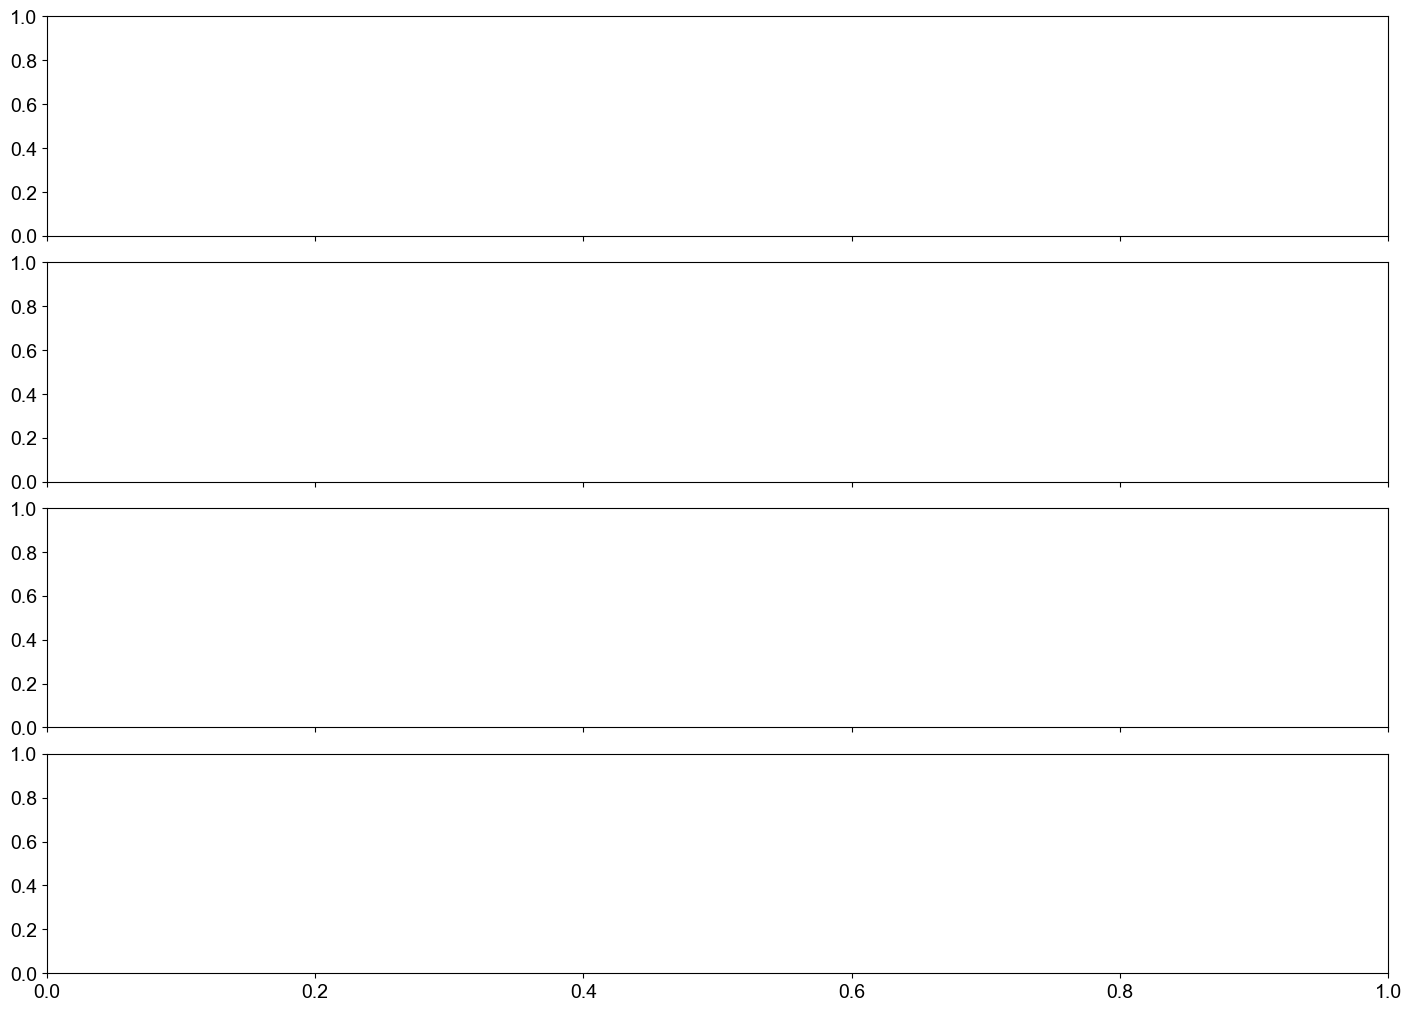

In [7]:
fig, axs = plt.subplots(4, 1, figsize=(14, 10), sharex=True, constrained_layout=True)

axs[0].plot(trel, z_proc["raw"], lw=0.8)
axs[0].set_ylabel("Raw counts")
axs[0].set_title(f"ELARM-SWP2 pipeline: {z_proc['id']}")

axs[1].plot(trel, z_proc["v"], lw=0.8, label="v (velocity)")
axs[1].plot(trel, z_proc["r_picker"], lw=0.8, label="r (picker high-pass)")
axs[1].set_ylabel("Filtered")
axs[1].legend(loc="upper right", fontsize=8)

axs[2].plot(trel, z_proc["ratio"], lw=0.8, label="STA/LTA")
axs[2].axhline(float(params["TrigLev"]), color="r", ls="--", lw=1.0, label="TrigLev")
axs[2].set_ylabel("STA/LTA")
axs[2].legend(loc="upper right", fontsize=8)

axs[3].plot(trel, z_proc["snr"], lw=0.8, label="S/N (ToGround)")
axs[3].set_ylabel("SNR")
axs[3].set_xlabel(f"Seconds since {zst[0].stats.starttime.isoformat()}")
axs[3].legend(loc="upper right", fontsize=8)

trigger_events = z_proc["trigger_events"]
for ev in trigger_events:
    x = ev.sample_time_epoch - t0
    for ax in axs:
        ax.axvline(x, color="k", alpha=0.25, lw=0.8)

In [ ]:
metrics = build_trigger_measurements(trigger_events, z_proc, n_proc, e_proc, params)

In [ ]:
metrics

20:22:01:135| INFO | N:H: sta chan net loc      lat       lon                    time up c  rsp  tsp            tp         tpsnr  dsp            pd         pdsnr  vsp            pv         pvsnr  asp            pa         pasnr    assoc tel tsec plen    sps toffset arrtime protime fndtime quetime sndtime  e2time buftime zc ne_to_z  acc_range


20:22:03:089| INFO | N: J0654  HLZ  KN  --  38.5769  141.4514 2026-08-20T20:22:02.860  0 Z    6    0  0.000000e+00  0.000000e+00    0  9.858536e-05  2.149358e-03    5 -2.335288e-03  2.143897e-03    2 -3.244113e-02  1.950128e-03  WAITING   0  0.0  100  100.0  0.9300  0.2267  0.2270  0.2275  0.2284  0.2286  0.0027  0.0027 22    0.00  0.000e+00

In [8]:
0.0025869399395162564

0.0025869399395162564

In [9]:
6.1e-2

0.061

## Updating again to give rolling trigger values

In [10]:
#!/usr/bin/env python3
"""
Plot ELARM-SWP2-style processing products from a MiniSEED file.

Outputs:
1) raw data
2) filtered data used by picker (high-pass r) plus velocity v
3) STA/LTA ratio time series
4) SNR time series (s/n from ToGround signal/noise channels)

Extras:
- trigger generation using PickerTSPModule logic
- per-trigger quality-check report showing pass criteria used by the picker
- per-trigger measurement fields aligned to TriggerParams logic
  (tp/tsp, pd/dsp, pv/vsp, pa/asp, SNR fields, ne_to_z, zc)
- optional streaming-style trigger update rows as data continues after each trigger

This script mirrors equations in:
- ToGroundTSPModule.cpp
- PickerTSPModule.cpp
- MaxAmpMeasure.cpp
- NEtoZMeasure.cpp
- ZeroCrossingsMeasure.cpp
and uses defaults from EWP2 params unless overridden by a params file.
"""

from __future__ import annotations

import argparse
import math
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
from obspy import read


# -----------------------------
# Parameter handling
# -----------------------------

DEFAULT_PARAMS: Dict[str, float | int | bool] = {
    # ToGround
    "HPFCAcceleration": 0.994,
    "HPFCVelocityA": 0.994,
    "HPFCVelocityV": 0.994,
    "HPFCDisplacement": 0.994,
    "TSCTauP": 1.0,
    "HPFCRaw": 0.994,
    "TSCTSignal": 0.05,
    "RICTauK": 3.0,
    "TSCTNoise": 30.0,
    # Picker
    "TSCTsta": 0.05,
    "TSCTlta": 5.0,
    "TrigLev": 20.0,
    "TrigDur": 10,
    "UseTrigStab": False,
    "TrigStabLev": 12.0,
    "UseTrigGapDelay": True,
    "TrigGapDur": 5,
    # Trigger metrics
    "ClipLevel": 6.0e12,
    "ClipDuration": 0.5,
    "TaupOutputDelay": 0.5,
    "MaxAmpBegLag": 0.1,
    "MaxAmpEndLag": 4.0,
    "StartNEtoZ": 0.0,
    "EndNEtoZ": 0.02,
    "ZCrossDemean": False,
    "ZCrossDemeanLead": 4.0,
    "ZCrossLead": 2.0,
    "ZCrossLag": 0.2,
}


def _parse_value(text: str):
    t = text.strip()
    if t.lower() in {"true", "false"}:
        return t.lower() == "true"
    try:
        if any(c in t.lower() for c in [".", "e"]):
            return float(t)
        return int(t)
    except ValueError:
        return t


def load_params(path: Optional[Path]) -> Dict[str, float | int | bool]:
    params = dict(DEFAULT_PARAMS)
    if path is None:
        return params

    with path.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            if "#" in line:
                line = line.split("#", 1)[0].strip()
            if not line:
                continue
            parts = line.split()
            if len(parts) < 2:
                continue
            key = parts[0]
            val = _parse_value(parts[1])
            params[key] = val

    return params


# -----------------------------
# ToGround implementation
# -----------------------------


@dataclass
class ToGroundState:
    was_gap: bool = True
    var_z0: float = 0.0
    var_a0: float = 0.0
    var_v0: float = 0.0
    var_d0: float = 0.0
    var_v1minus: float = 0.0
    var_vlp1minus: float = 0.0
    var_vlp0: float = 0.0
    var_sigma0: float = 0.0
    var_y0: float = 0.0
    var_r0: float = 0.0
    var_s0: float = 0.0
    var_n0: float = 0.0


class ToGroundProcessor:
    def __init__(self, channel_code: str, samplerate: float, gain: float, p: Dict):
        self.channel_code = channel_code
        self.samplerate = samplerate
        self.delta_t = 1.0 / samplerate
        self.gain = gain if gain != 0 else 1e-10

        # waveform type from channel[1] in C++
        c1 = channel_code[1] if len(channel_code) > 1 else "H"
        self.acceleration_input = c1 in {"N", "L"}

        self.q_acc = float(p["HPFCAcceleration"])
        self.q_vel_a = float(p["HPFCVelocityA"])
        self.q_vel_v = float(p["HPFCVelocityV"])
        self.q_disp = float(p["HPFCDisplacement"])
        self.lambda_taup = float(p["TSCTauP"])
        self.q_snr = float(p["HPFCRaw"])
        self.t_signal = float(p["TSCTSignal"])
        self.tau_k = float(p["RICTauK"])
        self.t_noise = float(p["TSCTNoise"])

        self.bg_for_accel = 2.0 * self.gain / (1.0 + self.q_acc)
        self.tg_for_accel = self.delta_t * self.gain
        self.t2b_for_velo = (1.0 + self.q_vel_a) * self.delta_t / 4.0
        self.bg_for_velo = 2.0 * self.gain / (1.0 + self.q_vel_v)
        self.t2b_for_disp = (1.0 + self.q_disp) * self.delta_t / 4.0

        self.alpha = (self.lambda_taup - self.delta_t) / self.lambda_taup
        self.alpha_signal = (self.t_signal - self.delta_t) / self.t_signal
        self.alpha_noise = (self.t_noise - self.delta_t) / self.t_noise

        # low-pass coeffs for vlp
        f_L = 1.8
        f = math.pi * f_L * self.delta_t
        fau = (1.0 / math.tan(f)) * (1.0 / math.tan(3.0 * f))
        self.gain_lp = 1.0 / (1.0 + math.sqrt(abs(2.0 * fau)) + fau)
        self.h1 = 2.0
        self.h2 = 1.0
        self.h3 = 2.0 * (1.0 - fau) * self.gain_lp
        self.h4 = 2.0 * (1.0 + fau) * self.gain_lp - 1.0

        self.state = ToGroundState()

    def restart(self):
        self.state = ToGroundState()

    def process(self, raw: np.ndarray) -> Dict[str, np.ndarray]:
        raw = raw.astype(np.float64, copy=False)
        n = raw.size
        out = {
            "raw": raw.copy(),
            "a": np.zeros(n, dtype=np.float64),
            "v": np.zeros(n, dtype=np.float64),
            "d": np.zeros(n, dtype=np.float64),
            "taup": np.zeros(n, dtype=np.float64),
            "s": np.zeros(n, dtype=np.float64),
            "n": np.zeros(n, dtype=np.float64),
            "r": np.zeros(n, dtype=np.float64),
        }

        if n == 0:
            return out

        st = self.state

        if st.was_gap:
            st.was_gap = False
            st.var_z0 = raw[0]

        # workspace
        vlp = np.zeros(n, dtype=np.float64)
        sigma = np.zeros(n, dtype=np.float64)
        y = np.zeros(n, dtype=np.float64)
        r = np.zeros(n, dtype=np.float64)

        # i = 0
        if self.acceleration_input:
            out["a"][0] = (raw[0] - st.var_z0) / self.bg_for_accel + self.q_acc * st.var_a0
            out["v"][0] = (out["a"][0] + st.var_a0) * self.t2b_for_velo + self.q_vel_a * st.var_v0
        else:
            out["a"][0] = (raw[0] - st.var_z0) / self.tg_for_accel
            out["v"][0] = (raw[0] - st.var_z0) / self.bg_for_velo + self.q_vel_v * st.var_v0

        out["d"][0] = (out["v"][0] + st.var_v0) * self.t2b_for_disp + self.q_disp * st.var_d0

        vlp[0] = (
            self.gain_lp * (out["v"][0] + self.h1 * st.var_v0 + self.h2 * st.var_v1minus)
            - self.h3 * st.var_vlp0
            - self.h4 * st.var_vlp1minus
        )
        sigma[0] = self.alpha * st.var_sigma0 + ((vlp[0] - st.var_vlp0) / self.delta_t) ** 2
        y[0] = self.alpha * st.var_y0 + vlp[0] ** 2

        lower = (0.01 / (2.0 * math.pi)) ** 2 * sigma[0]
        upper = (100.0 / (2.0 * math.pi)) ** 2 * sigma[0]
        if y[0] > lower and y[0] < upper:
            out["taup"][0] = 0.0 if sigma[0] == 0.0 else 2.0 * math.pi * math.sqrt(abs(y[0] / sigma[0]))

        r[0] = self.q_snr * st.var_r0 + raw[0] - st.var_z0
        cf0 = r[0] ** 2 + self.tau_k * (raw[0] - st.var_z0) ** 2
        out["s"][0] = self.alpha_signal * st.var_s0 + (1.0 - self.alpha_signal) * cf0
        out["n"][0] = self.alpha_noise * st.var_n0 + (1.0 - self.alpha_noise) * cf0

        # i >= 1
        for i in range(1, n):
            dz = raw[i] - raw[i - 1]
            if self.acceleration_input:
                out["a"][i] = dz / self.bg_for_accel + self.q_acc * out["a"][i - 1]
                out["v"][i] = (out["a"][i] + out["a"][i - 1]) * self.t2b_for_velo + self.q_vel_a * out["v"][i - 1]
            else:
                out["a"][i] = dz / self.tg_for_accel
                out["v"][i] = dz / self.bg_for_velo + self.q_vel_v * out["v"][i - 1]

            out["d"][i] = (out["v"][i] + out["v"][i - 1]) * self.t2b_for_disp + self.q_disp * out["d"][i - 1]

            if i == 1:
                vlp[i] = (
                    self.gain_lp * (out["v"][i] + self.h1 * out["v"][i - 1] + self.h2 * st.var_v0)
                    - self.h3 * vlp[i - 1]
                    - self.h4 * st.var_vlp0
                )
            else:
                vlp[i] = (
                    self.gain_lp * (out["v"][i] + self.h1 * out["v"][i - 1] + self.h2 * out["v"][i - 2])
                    - self.h3 * vlp[i - 1]
                    - self.h4 * vlp[i - 2]
                )

            sigma[i] = self.alpha * sigma[i - 1] + ((vlp[i] - vlp[i - 1]) / self.delta_t) ** 2
            y[i] = self.alpha * y[i - 1] + vlp[i] ** 2

            lower = (0.01 / (2.0 * math.pi)) ** 2 * sigma[i]
            upper = (100.0 / (2.0 * math.pi)) ** 2 * sigma[i]
            if y[i] > lower and y[i] < upper:
                out["taup"][i] = 0.0 if sigma[i] == 0.0 else 2.0 * math.pi * math.sqrt(abs(y[i] / sigma[i]))
            else:
                out["taup"][i] = 0.0

            r[i] = self.q_snr * r[i - 1] + dz
            cf = r[i] ** 2 + self.tau_k * dz ** 2
            out["s"][i] = self.alpha_signal * out["s"][i - 1] + (1.0 - self.alpha_signal) * cf
            out["n"][i] = self.alpha_noise * out["n"][i - 1] + (1.0 - self.alpha_noise) * cf

        out["r"] = r

        # update state
        st.var_z0 = raw[-1]
        st.var_a0 = out["a"][-1]
        st.var_v0 = out["v"][-1]
        st.var_d0 = out["d"][-1]
        st.var_vlp0 = vlp[-1]
        if n > 2:
            st.var_v1minus = out["v"][-2]
            st.var_vlp1minus = vlp[-2]
        else:
            st.var_v1minus = 0.0
            st.var_vlp1minus = 0.0
        st.var_sigma0 = sigma[-1]
        st.var_y0 = y[-1]
        st.var_r0 = r[-1]
        st.var_s0 = out["s"][-1]
        st.var_n0 = out["n"][-1]

        return out


# -----------------------------
# Picker implementation + trigger quality checks
# -----------------------------


@dataclass
class PickerState:
    prev_r: float = 0.0
    prev_v: float = 0.0
    prev_sta: float = 0.0
    prev_lta: float = 0.0
    stabilized: bool = False
    in_gap: bool = True
    time_untrig: float = 0.0
    time_gap_delay: float = 0.0


@dataclass
class TriggerEvent:
    sample_index: int
    sample_time_epoch: float
    sta: float
    lta: float
    ratio: float
    trig_level: float
    trig_stab_level: float
    stabilized: bool
    passed_stab_check: bool
    passed_gap_delay_check: bool
    passed_untrig_check: bool
    passed_ratio_check: bool
    gap_delay_until_epoch: float
    untrig_until_epoch: float
    r_picker: float
    passed_all_checks: bool


class PickerProcessor:
    def __init__(self, params: Dict):
        self.q_raw = float(params["HPFCRaw"])
        self.t_sta = max(float(params["TSCTsta"]), 1e-10)
        self.t_lta = max(float(params["TSCTlta"]), 1e-10)
        self.tau_k = float(params["RICTauK"])
        self.trig_lev = float(params["TrigLev"])
        self.trig_dur = int(params["TrigDur"])
        self.use_trig_stab = bool(params["UseTrigStab"])
        self.trig_stab_lev = float(params["TrigStabLev"])
        self.use_trig_gap_delay = bool(params["UseTrigGapDelay"])
        self.trig_gap_dur = int(params["TrigGapDur"])

        self.state = PickerState(stabilized=(False if self.use_trig_stab else True))

    def restart(self, sample_time: float):
        _ = sample_time
        self.state.prev_r = 0.0
        self.state.prev_v = 0.0
        self.state.prev_sta = 0.0
        self.state.prev_lta = 0.0
        self.state.in_gap = True
        if self.use_trig_stab:
            self.state.stabilized = False

    def _evaluate_checks(self, sample_time: float, sta_i: float, lta_i: float, stabilized: bool) -> Dict[str, bool | float]:
        ratio = (sta_i / lta_i) if lta_i != 0.0 else 0.0
        passed_ratio_check = sta_i > self.trig_lev * lta_i
        passed_stab_check = stabilized
        passed_gap_delay_check = (sample_time > self.state.time_gap_delay) if self.use_trig_gap_delay else True
        passed_untrig_check = sample_time > self.state.time_untrig

        passed_all = passed_ratio_check and passed_stab_check and passed_gap_delay_check and passed_untrig_check
        return {
            "ratio": ratio,
            "passed_ratio_check": passed_ratio_check,
            "passed_stab_check": passed_stab_check,
            "passed_gap_delay_check": passed_gap_delay_check,
            "passed_untrig_check": passed_untrig_check,
            "passed_all_checks": passed_all,
        }

    def process(self, v: np.ndarray, first_sample_time: float, samplerate: float) -> Dict[str, np.ndarray | List[TriggerEvent]]:
        n = len(v)
        r = np.zeros(n, dtype=np.float64)
        sta = np.zeros(n, dtype=np.float64)
        lta = np.zeros(n, dtype=np.float64)
        trigger_events: List[TriggerEvent] = []

        if n == 0:
            return {
                "r_picker": r,
                "sta": sta,
                "lta": lta,
                "ratio": np.zeros(0, dtype=np.float64),
                "trigger_events": trigger_events,
            }

        st = self.state
        if st.in_gap:
            st.in_gap = False
            st.time_gap_delay = first_sample_time + abs(float(self.trig_gap_dur))

        delta_t = 1.0 / samplerate
        alpha_1_sta = delta_t / self.t_sta
        alpha_1_lta = delta_t / self.t_lta
        alpha_sta = 1.0 - alpha_1_sta
        alpha_lta = 1.0 - alpha_1_lta

        r[0] = self.q_raw * st.prev_r + (v[0] - st.prev_v)
        cf0 = r[0] ** 2 + self.tau_k * (v[0] - st.prev_v) ** 2
        sta[0] = alpha_sta * st.prev_sta + alpha_1_sta * cf0
        lta[0] = alpha_lta * st.prev_lta + alpha_1_lta * cf0

        if sta[0] < self.trig_stab_lev * lta[0]:
            st.stabilized = True

        checks0 = self._evaluate_checks(first_sample_time, sta[0], lta[0], st.stabilized)
        if checks0["passed_all_checks"]:
            trigger_events.append(
                TriggerEvent(
                    sample_index=0,
                    sample_time_epoch=first_sample_time,
                    sta=float(sta[0]),
                    lta=float(lta[0]),
                    ratio=float(checks0["ratio"]),
                    trig_level=self.trig_lev,
                    trig_stab_level=self.trig_stab_lev,
                    stabilized=st.stabilized,
                    passed_stab_check=bool(checks0["passed_stab_check"]),
                    passed_gap_delay_check=bool(checks0["passed_gap_delay_check"]),
                    passed_untrig_check=bool(checks0["passed_untrig_check"]),
                    passed_ratio_check=bool(checks0["passed_ratio_check"]),
                    gap_delay_until_epoch=st.time_gap_delay,
                    untrig_until_epoch=first_sample_time + self.trig_dur,
                    r_picker=float(r[0]),
                    passed_all_checks=bool(checks0["passed_all_checks"]),
                )
            )
            st.time_untrig = first_sample_time + self.trig_dur

        for i in range(1, n):
            sample_time = first_sample_time + i * delta_t
            r[i] = self.q_raw * r[i - 1] + (v[i] - v[i - 1])
            cfi = r[i] ** 2 + self.tau_k * (v[i] - v[i - 1]) ** 2
            sta[i] = alpha_sta * sta[i - 1] + alpha_1_sta * cfi
            lta[i] = alpha_lta * lta[i - 1] + alpha_1_lta * cfi

            if sta[i] < self.trig_stab_lev * lta[i]:
                st.stabilized = True

            checks = self._evaluate_checks(sample_time, sta[i], lta[i], st.stabilized)
            if checks["passed_all_checks"]:
                trigger_events.append(
                    TriggerEvent(
                        sample_index=i,
                        sample_time_epoch=sample_time,
                        sta=float(sta[i]),
                        lta=float(lta[i]),
                        ratio=float(checks["ratio"]),
                        trig_level=self.trig_lev,
                        trig_stab_level=self.trig_stab_lev,
                        stabilized=st.stabilized,
                        passed_stab_check=bool(checks["passed_stab_check"]),
                        passed_gap_delay_check=bool(checks["passed_gap_delay_check"]),
                        passed_untrig_check=bool(checks["passed_untrig_check"]),
                        passed_ratio_check=bool(checks["passed_ratio_check"]),
                        gap_delay_until_epoch=st.time_gap_delay,
                        untrig_until_epoch=sample_time + self.trig_dur,
                        r_picker=float(r[i]),
                        passed_all_checks=bool(checks["passed_all_checks"]),
                    )
                )
                st.time_untrig = sample_time + self.trig_dur

        st.prev_v = float(v[-1])
        st.prev_r = float(r[-1])
        st.prev_sta = float(sta[-1])
        st.prev_lta = float(lta[-1])

        ratio = np.divide(sta, lta, out=np.zeros_like(sta), where=lta != 0.0)
        return {
            "r_picker": r,
            "sta": sta,
            "lta": lta,
            "ratio": ratio,
            "trigger_events": trigger_events,
        }


# -----------------------------
# End-to-end on a single trace
# -----------------------------


def _channel_triplet(stream, preferred_channel: Optional[str]):
    if preferred_channel:
        z = stream.select(channel=preferred_channel)
        if len(z) == 0:
            raise ValueError(f"No trace matches --channel={preferred_channel}")
        base = preferred_channel[:-1]
        z = z[0]
        n = stream.select(channel=base + "N")
        e = stream.select(channel=base + "E")
        return z, (n[0] if len(n) else None), (e[0] if len(e) else None)

    z = stream.select(channel="*Z")
    if len(z) == 0:
        raise ValueError("No *Z trace found in input")
    z = z[0]
    base = z.stats.channel[:-1]
    n = stream.select(channel=base + "N")
    e = stream.select(channel=base + "E")
    return z, (n[0] if len(n) else None), (e[0] if len(e) else None)


def _process_component(trace, params: Dict, gain_override: Optional[float], run_picker: bool) -> Optional[Dict]:
    if trace is None:
        return None

    raw = trace.data.astype(np.float64)
    sr = float(trace.stats.sampling_rate)
    gain = float(gain_override) if gain_override is not None else 1.0

    tg = ToGroundProcessor(
        channel_code=str(trace.stats.channel),
        samplerate=sr,
        gain=gain,
        p=params,
    )
    tg_out = tg.process(raw)

    t = trace.stats.starttime.timestamp + np.arange(raw.size, dtype=np.float64) / sr

    out = {
        "id": f"{trace.stats.network}.{trace.stats.station}.{trace.stats.location}.{trace.stats.channel}",
        "t": t,
        "start_epoch": float(trace.stats.starttime.timestamp),
        "sr": sr,
        "raw": tg_out["raw"],
        "a": tg_out["a"],
        "v": tg_out["v"],
        "d": tg_out["d"],
        "taup": tg_out["taup"],
        "s": tg_out["s"],
        "n": tg_out["n"],
    }

    out["snr"] = np.divide(out["s"], out["n"], out=np.zeros_like(out["s"]), where=out["n"] != 0.0)

    if run_picker:
        picker = PickerProcessor(params)
        po = picker.process(out["v"], t[0], sr)
        out["r_picker"] = po["r_picker"]
        out["sta"] = po["sta"]
        out["lta"] = po["lta"]
        out["ratio"] = po["ratio"]
        out["trigger_events"] = po["trigger_events"]
    else:
        out["r_picker"] = tg_out["r"]
        out["sta"] = np.zeros_like(out["v"])
        out["lta"] = np.zeros_like(out["v"])
        out["ratio"] = np.zeros_like(out["v"])
        out["trigger_events"] = []

    return out


# -----------------------------
# Trigger-parameter measurements
# -----------------------------


@dataclass
class TriggerMeasurements:
    sample_index: int
    time_epoch: float
    time_rel_s: float
    tsp: int
    tp: float
    tpsnr: float
    dsp: int
    pd: float
    pdsnr: float
    vsp: int
    pv: float
    pvsnr: float
    asp: int
    pa: float
    pasnr: float
    ne_to_z: float
    zc: int
    zc_vel: int
    zc_acc: int
    passed_ratio_check: int
    passed_stab_check: int
    passed_gap_delay_check: int
    passed_untrig_check: int
    passed_all_checks: int


@dataclass
class TriggerUpdateRow:
    trigger_index: int
    trigger_sample_index: int
    trigger_time_epoch: float
    update_sample_index: int
    update_time_epoch: float
    update_time_rel_s: float
    maxamp_status: str
    ne_to_z_status: str
    zc_status: str
    tsp: int
    tp: float
    tpsnr: float
    dsp: int
    pd: float
    pdsnr: float
    vsp: int
    pv: float
    pvsnr: float
    asp: int
    pa: float
    pasnr: float
    ne_to_z: float
    zc: int
    zc_vel: int
    zc_acc: int



def _compute_maxamp_metrics_until(z: Dict, trig_idx: int, end_idx: int, params: Dict):
    t = z["t"]
    a = z["a"]
    v = z["v"]
    d = z["d"]
    taup = z["taup"]
    s = z["s"]
    n = z["n"]
    sr = float(z["sr"])

    half_dt = 0.5 / sr
    dt = 1.0 / sr
    trigger_time = t[trig_idx]
    end_lag = float(params.get("MaxAmpEndLag", 4.0))
    beg_lag = float(params.get("MaxAmpBegLag", 0.1))
    taup_output_delay = float(params.get("TaupOutputDelay", 0.5))
    clip_level = float(params.get("ClipLevel", 6.0e12))
    clip_duration = float(params.get("ClipDuration", 0.5))

    pa = pv = pd = tp = 0.0
    asp = vsp = dsp = tsp = 0
    pasnr = pvsnr = pdsnr = tpsnr = -1.0

    noise = n[trig_idx] if 0 <= trig_idx < n.size else 0.0
    time_unclip = 0.0
    snr_i = -1.0

    if t.size == 0 or trig_idx < 0 or trig_idx >= t.size:
        return {
            "tsp": tsp, "tp": tp, "tpsnr": tpsnr, "dsp": dsp, "pd": pd, "pdsnr": pdsnr,
            "vsp": vsp, "pv": pv, "pvsnr": pvsnr, "asp": asp, "pa": pa, "pasnr": pasnr,
            "status": "waiting",
        }

    hard_end_time = trigger_time + end_lag + half_dt
    i = trig_idx
    last_processed_time = trigger_time - dt
    max_i = min(end_idx, t.size - 1)

    while i <= max_i:
        sample_time = t[i]
        if sample_time > hard_end_time:
            break

        last_processed_time = sample_time

        if abs(sample_time - trigger_time) < half_dt:
            noise = n[i]

        if time_unclip > 0.0:
            if sample_time > time_unclip:
                if abs(s[i]) > clip_level:
                    time_unclip += clip_duration
                    snr_i = -1.0
                else:
                    time_unclip = 0.0
                    snr_i = 0.0 if noise == 0.0 else s[i] / noise
            else:
                snr_i = -1.0
        else:
            if abs(s[i]) > clip_level:
                time_unclip = sample_time + clip_duration
                snr_i = -1.0
            else:
                time_unclip = 0.0
                snr_i = 0.0 if noise == 0.0 else s[i] / noise

        off = int((sample_time - trigger_time) * sr + 0.5)

        if abs(pa) < abs(a[i]):
            pa = float(a[i])
            pasnr = float(snr_i)
            asp = off

        if abs(pv) < abs(v[i]):
            pv = float(v[i])
            pvsnr = float(snr_i)
            vsp = off

        if abs(pd) < abs(d[i]):
            pd = float(d[i])
            pdsnr = float(snr_i)
            dsp = off

        if sample_time - trigger_time > taup_output_delay and tp < taup[i]:
            tp = float(taup[i])
            tpsnr = float(snr_i)
            tsp = off

        i += 1

    next_sample = last_processed_time + dt
    if next_sample > trigger_time + end_lag + half_dt:
        status = "complete"
    elif next_sample > trigger_time + beg_lag + half_dt:
        status = "updating"
    else:
        status = "waiting"

    return {
        "tsp": tsp,
        "tp": tp,
        "tpsnr": tpsnr,
        "dsp": dsp,
        "pd": pd,
        "pdsnr": pdsnr,
        "vsp": vsp,
        "pv": pv,
        "pvsnr": pvsnr,
        "asp": asp,
        "pa": pa,
        "pasnr": pasnr,
        "status": status,
    }


def _compute_maxamp_metrics(z: Dict, trig_idx: int, params: Dict):
    return _compute_maxamp_metrics_until(z, trig_idx, z["t"].size - 1, params)



def _window_values(t: np.ndarray, x: np.ndarray, tmin: float, tmax: float) -> np.ndarray:
    if t.size == 0 or x.size == 0:
        return np.zeros(0, dtype=float)
    m = (t > tmin) & (t < tmax)
    return x[m]


def _compute_ne_to_z(z: Dict, n_comp: Optional[Dict], e_comp: Optional[Dict], trigger_time: float, params: Dict):
    if n_comp is None or e_comp is None:
        return float("nan")

    sr = float(z["sr"])
    half_dt = 0.5 / sr
    start_lag = float(params.get("StartNEtoZ", 0.0))
    end_lag = float(params.get("EndNEtoZ", 0.05))
    tmin = trigger_time + start_lag - half_dt
    tmax = trigger_time + end_lag + half_dt

    zv = _window_values(z["t"], z["v"], tmin, tmax)
    nv = _window_values(n_comp["t"], n_comp["v"], tmin, tmax)
    ev = _window_values(e_comp["t"], e_comp["v"], tmin, tmax)

    if zv.size == 0 or nv.size == 0 or ev.size == 0:
        return float("nan")

    n_range = float(np.max(nv) - np.min(nv))
    e_range = float(np.max(ev) - np.min(ev))
    z_range = float(np.max(zv) - np.min(zv))

    if z_range == 0.0:
        return 0.0
    return max(n_range, e_range) / z_range


def _compute_zero_crossings(z: Dict, trigger_time: float, params: Dict):
    t = z["t"]
    v = z["v"]
    a = z["a"]
    if t.size == 0:
        return -1, -1, -1

    sr = float(z["sr"])
    half_dt = 0.5 / sr
    demean = bool(params.get("ZCrossDemean", True))
    demean_lead = float(params.get("ZCrossDemeanLead", 4.0))
    lead = float(params.get("ZCrossLead", 2.0))
    lag = float(params.get("ZCrossLag", 0.2))

    mean_start = trigger_time - demean_lead - half_dt
    cnt_start = trigger_time - lead - half_dt
    cnt_end = trigger_time + lag + half_dt

    mean_vel = 0.0
    mean_acc = 0.0
    if demean:
        mm = t > mean_start
        if np.any(mm):
            mean_vel = float(np.mean(v[mm]))
            mean_acc = float(np.mean(a[mm]))

    m = (t > cnt_start) & (t < cnt_end)
    if not np.any(m):
        return -1, -1, -1

    vv = v[m]
    zero_cross_vel = -1
    zero_cross_acc = -1
    crossing_greater_vel = False
    crossing_greater_acc = False

    for val in vv:
        if zero_cross_vel < 0:
            zero_cross_vel = 0
            crossing_greater_vel = val > mean_vel
        else:
            curr = val > mean_vel
            if curr != crossing_greater_vel:
                crossing_greater_vel = curr
                zero_cross_vel += 1

        # NOTE: source code compares zdata.v to mean_acc here (not zdata.a).
        if zero_cross_acc < 0:
            zero_cross_acc = 0
            crossing_greater_acc = val > mean_acc
        else:
            curr = val > mean_acc
            if curr != crossing_greater_acc:
                crossing_greater_acc = curr
                zero_cross_acc += 1

    if zero_cross_vel < 0 and zero_cross_acc < 0:
        zc = -1
    elif zero_cross_vel < 0:
        zc = zero_cross_acc
    elif zero_cross_acc < 0:
        zc = zero_cross_vel
    else:
        zc = min(zero_cross_vel, zero_cross_acc)

    return int(zc), int(zero_cross_vel), int(zero_cross_acc)


def _compute_ne_to_z_until(
    z: Dict,
    n_comp: Optional[Dict],
    e_comp: Optional[Dict],
    trigger_time: float,
    params: Dict,
    end_time: float,
):
    if n_comp is None or e_comp is None:
        return float("nan"), "missing_components"

    sr = float(z["sr"])
    half_dt = 0.5 / sr
    start_lag = float(params.get("StartNEtoZ", 0.0))
    end_lag = float(params.get("EndNEtoZ", 0.05))
    tmin = trigger_time + start_lag - half_dt
    tmax = trigger_time + end_lag + half_dt

    zmask = (z["t"] > tmin) & (z["t"] < tmax) & (z["t"] <= end_time)
    nmask = (n_comp["t"] > tmin) & (n_comp["t"] < tmax) & (n_comp["t"] <= end_time)
    emask = (e_comp["t"] > tmin) & (e_comp["t"] < tmax) & (e_comp["t"] <= end_time)

    zv = z["v"][zmask]
    nv = n_comp["v"][nmask]
    ev = e_comp["v"][emask]

    status = "complete" if end_time > tmax else "waiting"
    if zv.size == 0 or nv.size == 0 or ev.size == 0:
        return float("nan"), status

    n_range = float(np.max(nv) - np.min(nv))
    e_range = float(np.max(ev) - np.min(ev))
    z_range = float(np.max(zv) - np.min(zv))

    if z_range == 0.0:
        return 0.0, status
    return max(n_range, e_range) / z_range, status


def _compute_zero_crossings_until(z: Dict, trigger_time: float, params: Dict, end_time: float):
    t = z["t"]
    v = z["v"]
    a = z["a"]
    if t.size == 0:
        return -1, -1, -1, "waiting"

    sr = float(z["sr"])
    half_dt = 0.5 / sr
    demean = bool(params.get("ZCrossDemean", True))
    demean_lead = float(params.get("ZCrossDemeanLead", 4.0))
    lead = float(params.get("ZCrossLead", 2.0))
    lag = float(params.get("ZCrossLag", 0.2))

    mean_start = trigger_time - demean_lead - half_dt
    cnt_start = trigger_time - lead - half_dt
    cnt_end = trigger_time + lag + half_dt

    # Only use data available up to end_time for streaming-like updates.
    avail = t <= end_time
    if not np.any(avail):
        return -1, -1, -1, "waiting"

    mean_vel = 0.0
    mean_acc = 0.0
    if demean:
        mm = (t > mean_start) & avail
        if np.any(mm):
            mean_vel = float(np.mean(v[mm]))
            mean_acc = float(np.mean(a[mm]))

    m = (t > cnt_start) & (t < cnt_end) & avail
    if not np.any(m):
        status = "complete" if end_time > cnt_end else "waiting"
        return -1, -1, -1, status

    vv = v[m]
    zero_cross_vel = -1
    zero_cross_acc = -1
    crossing_greater_vel = False
    crossing_greater_acc = False

    for val in vv:
        if zero_cross_vel < 0:
            zero_cross_vel = 0
            crossing_greater_vel = val > mean_vel
        else:
            curr = val > mean_vel
            if curr != crossing_greater_vel:
                crossing_greater_vel = curr
                zero_cross_vel += 1

        # NOTE: source code compares zdata.v to mean_acc here (not zdata.a).
        if zero_cross_acc < 0:
            zero_cross_acc = 0
            crossing_greater_acc = val > mean_acc
        else:
            curr = val > mean_acc
            if curr != crossing_greater_acc:
                crossing_greater_acc = curr
                zero_cross_acc += 1

    if zero_cross_vel < 0 and zero_cross_acc < 0:
        zc = -1
    elif zero_cross_vel < 0:
        zc = zero_cross_acc
    elif zero_cross_acc < 0:
        zc = zero_cross_vel
    else:
        zc = min(zero_cross_vel, zero_cross_acc)

    status = "complete" if end_time > cnt_end else "waiting"
    return int(zc), int(zero_cross_vel), int(zero_cross_acc), status


def build_trigger_updates(
    trigger_events: List[TriggerEvent],
    z_proc: Dict,
    n_proc: Optional[Dict],
    e_proc: Optional[Dict],
    params: Dict,
    step_samples: int = 1,
) -> List[TriggerUpdateRow]:
    rows: List[TriggerUpdateRow] = []
    if not trigger_events:
        return rows

    sr = float(z_proc["sr"])
    half_dt = 0.5 / sr
    t0 = z_proc["start_epoch"]
    t = z_proc["t"]
    max_amp_end_lag = float(params.get("MaxAmpEndLag", 4.0))
    ne_end_lag = float(params.get("EndNEtoZ", 0.05))
    zc_lag = float(params.get("ZCrossLag", 0.2))
    max_lag = max(max_amp_end_lag, ne_end_lag, zc_lag)

    step = max(1, int(step_samples))

    for trig_num, ev in enumerate(trigger_events, start=1):
        trig_idx = int(ev.sample_index)
        if trig_idx < 0 or trig_idx >= t.size:
            continue
        trigger_time = float(t[trig_idx])

        end_time = trigger_time + max_lag + half_dt
        end_idx = int(np.searchsorted(t, end_time, side="right") - 1)
        if end_idx < trig_idx:
            end_idx = trig_idx

        i = trig_idx
        while i <= end_idx:
            sample_time = float(t[i])

            ma = _compute_maxamp_metrics_until(z_proc, trig_idx, i, params)
            ne_to_z, ne_status = _compute_ne_to_z_until(
                z_proc, n_proc, e_proc, trigger_time, params, sample_time
            )
            zc, zc_vel, zc_acc, zc_status = _compute_zero_crossings_until(
                z_proc, trigger_time, params, sample_time
            )

            rows.append(
                TriggerUpdateRow(
                    trigger_index=trig_num,
                    trigger_sample_index=trig_idx,
                    trigger_time_epoch=trigger_time,
                    update_sample_index=i,
                    update_time_epoch=sample_time,
                    update_time_rel_s=sample_time - t0,
                    maxamp_status=str(ma["status"]),
                    ne_to_z_status=ne_status,
                    zc_status=zc_status,
                    tsp=int(ma["tsp"]),
                    tp=float(ma["tp"]),
                    tpsnr=float(ma["tpsnr"]),
                    dsp=int(ma["dsp"]),
                    pd=float(ma["pd"]),
                    pdsnr=float(ma["pdsnr"]),
                    vsp=int(ma["vsp"]),
                    pv=float(ma["pv"]),
                    pvsnr=float(ma["pvsnr"]),
                    asp=int(ma["asp"]),
                    pa=float(ma["pa"]),
                    pasnr=float(ma["pasnr"]),
                    ne_to_z=float(ne_to_z),
                    zc=int(zc),
                    zc_vel=int(zc_vel),
                    zc_acc=int(zc_acc),
                )
            )

            i += step

        if rows and rows[-1].update_sample_index != end_idx:
            sample_time = float(t[end_idx])
            ma = _compute_maxamp_metrics_until(z_proc, trig_idx, end_idx, params)
            ne_to_z, ne_status = _compute_ne_to_z_until(
                z_proc, n_proc, e_proc, trigger_time, params, sample_time
            )
            zc, zc_vel, zc_acc, zc_status = _compute_zero_crossings_until(
                z_proc, trigger_time, params, sample_time
            )
            rows.append(
                TriggerUpdateRow(
                    trigger_index=trig_num,
                    trigger_sample_index=trig_idx,
                    trigger_time_epoch=trigger_time,
                    update_sample_index=end_idx,
                    update_time_epoch=sample_time,
                    update_time_rel_s=sample_time - t0,
                    maxamp_status=str(ma["status"]),
                    ne_to_z_status=ne_status,
                    zc_status=zc_status,
                    tsp=int(ma["tsp"]),
                    tp=float(ma["tp"]),
                    tpsnr=float(ma["tpsnr"]),
                    dsp=int(ma["dsp"]),
                    pd=float(ma["pd"]),
                    pdsnr=float(ma["pdsnr"]),
                    vsp=int(ma["vsp"]),
                    pv=float(ma["pv"]),
                    pvsnr=float(ma["pvsnr"]),
                    asp=int(ma["asp"]),
                    pa=float(ma["pa"]),
                    pasnr=float(ma["pasnr"]),
                    ne_to_z=float(ne_to_z),
                    zc=int(zc),
                    zc_vel=int(zc_vel),
                    zc_acc=int(zc_acc),
                )
            )

    return rows


def write_trigger_updates_csv(path: Path, updates: List[TriggerUpdateRow]) -> None:
    header = (
        "trigger_index,trigger_sample_index,trigger_time_epoch,"
        "update_sample_index,update_time_epoch,update_time_rel_s,"
        "maxamp_status,ne_to_z_status,zc_status,"
        "tsp,tp,tpsnr,dsp,pd,pdsnr,vsp,pv,pvsnr,asp,pa,pasnr,ne_to_z,zc,zc_vel,zc_acc"
    )
    path.parent.mkdir(parents=True, exist_ok=True)

    with path.open("w", encoding="utf-8") as f:
        f.write(header + "\n")
        for u in updates:
            f.write(
                f"{u.trigger_index},{u.trigger_sample_index},{u.trigger_time_epoch:.6f},"
                f"{u.update_sample_index},{u.update_time_epoch:.6f},{u.update_time_rel_s:.6f},"
                f"{u.maxamp_status},{u.ne_to_z_status},{u.zc_status},"
                f"{u.tsp},{u.tp:.9g},{u.tpsnr:.9g},{u.dsp},{u.pd:.9g},{u.pdsnr:.9g},"
                f"{u.vsp},{u.pv:.9g},{u.pvsnr:.9g},{u.asp},{u.pa:.9g},{u.pasnr:.9g},"
                f"{u.ne_to_z:.9g},{u.zc},{u.zc_vel},{u.zc_acc}\n"
            )

    print(f"Wrote trigger-updates CSV: {path} ({len(updates)} rows)")
def build_trigger_measurements(
    trigger_events: List[TriggerEvent],
    z_proc: Dict,
    n_proc: Optional[Dict],
    e_proc: Optional[Dict],
    params: Dict,
) -> List[TriggerMeasurements]:
    rows: List[TriggerMeasurements] = []
    if not trigger_events:
        return rows

    t0 = z_proc["start_epoch"]
    for ev in trigger_events:
        if ev.sample_index < 0 or ev.sample_index >= z_proc["t"].size:
            continue

        trig_time = float(z_proc["t"][ev.sample_index])

        ma = _compute_maxamp_metrics(z_proc, ev.sample_index, params)
        ne_to_z = _compute_ne_to_z(z_proc, n_proc, e_proc, trig_time, params)
        zc, zc_vel, zc_acc = _compute_zero_crossings(z_proc, trig_time, params)

        rows.append(
            TriggerMeasurements(
                sample_index=int(ev.sample_index),
                time_epoch=trig_time,
                time_rel_s=trig_time - t0,
                tsp=int(ma["tsp"]),
                tp=float(ma["tp"]),
                tpsnr=float(ma["tpsnr"]),
                dsp=int(ma["dsp"]),
                pd=float(ma["pd"]),
                pdsnr=float(ma["pdsnr"]),
                vsp=int(ma["vsp"]),
                pv=float(ma["pv"]),
                pvsnr=float(ma["pvsnr"]),
                asp=int(ma["asp"]),
                pa=float(ma["pa"]),
                pasnr=float(ma["pasnr"]),
                ne_to_z=float(ne_to_z),
                zc=int(zc),
                zc_vel=int(zc_vel),
                zc_acc=int(zc_acc),
                passed_ratio_check=int(ev.passed_ratio_check),
                passed_stab_check=int(ev.passed_stab_check),
                passed_gap_delay_check=int(ev.passed_gap_delay_check),
                passed_untrig_check=int(ev.passed_untrig_check),
                passed_all_checks=int(ev.passed_all_checks),
            )
        )
    return rows


def print_trigger_report(trigger_events: List[TriggerEvent], metrics: List[TriggerMeasurements]) -> None:
    if not trigger_events:
        print("No triggers found.")
        return

    print(f"Found {len(trigger_events)} triggers")
    print(
        "idx,time_rel_s,tsp,tp,tpsnr,dsp,pd,pdsnr,vsp,pv,pvsnr,asp,pa,pasnr,ne_to_z,zc,"
        "ratio_ok,stab_ok,gap_ok,untrig_ok,all_ok"
    )
    for m in metrics:
        ne = "nan" if not np.isfinite(m.ne_to_z) else f"{m.ne_to_z:.4f}"
        print(
            f"{m.sample_index},{m.time_rel_s:.4f},{m.tsp},{m.tp:.6g},{m.tpsnr:.6g},"
            f"{m.dsp},{m.pd:.6g},{m.pdsnr:.6g},{m.vsp},{m.pv:.6g},{m.pvsnr:.6g},"
            f"{m.asp},{m.pa:.6g},{m.pasnr:.6g},{ne},{m.zc},"
            f"{m.passed_ratio_check},{m.passed_stab_check},{m.passed_gap_delay_check},"
            f"{m.passed_untrig_check},{m.passed_all_checks}"
        )


def write_trigger_csv(path: Path, metrics: List[TriggerMeasurements]) -> None:
    header = (
        "sample_index,time_epoch,time_rel_s,"
        "tsp,tp,tpsnr,dsp,pd,pdsnr,vsp,pv,pvsnr,asp,pa,pasnr,"
        "ne_to_z,zc,zc_vel,zc_acc,"
        "passed_ratio_check,passed_stab_check,passed_gap_delay_check,passed_untrig_check,passed_all_checks"
    )
    rows = []
    for m in metrics:
        rows.append(
            [
                m.sample_index,
                m.time_epoch,
                m.time_rel_s,
                m.tsp,
                m.tp,
                m.tpsnr,
                m.dsp,
                m.pd,
                m.pdsnr,
                m.vsp,
                m.pv,
                m.pvsnr,
                m.asp,
                m.pa,
                m.pasnr,
                m.ne_to_z,
                m.zc,
                m.zc_vel,
                m.zc_acc,
                m.passed_ratio_check,
                m.passed_stab_check,
                m.passed_gap_delay_check,
                m.passed_untrig_check,
                m.passed_all_checks,
            ]
        )

    arr = np.asarray(rows, dtype=float) if rows else np.empty((0, 24), dtype=float)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savetxt(path, arr, delimiter=",", header=header, comments="")
    print(f"Wrote trigger CSV: {path}")


# -----------------------------
# Main
# -----------------------------


def main():
    ap = argparse.ArgumentParser(description="Plot ELARM-SWP2 processing from MiniSEED")
    ap.add_argument("mseed", type=Path, help="Input MiniSEED file")
    ap.add_argument("--params", type=Path, default=None, help="Optional EWP2 params file")
    ap.add_argument("--channel", default=None, help="Reference channel selector (e.g., HNZ)")
    ap.add_argument("--gain", type=float, default=None, help="Override gain (counts per unit)")
    ap.add_argument("--out", type=Path, default=Path("ewp2_pipeline_plot.png"), help="Output PNG")
    ap.add_argument("--csv", type=Path, default=None, help="Optional output time-series CSV")
    ap.add_argument("--trigger-csv", type=Path, default=None, help="Optional per-trigger final metrics CSV")
    ap.add_argument("--trigger-updates-csv", type=Path, default=None, help="Optional per-update trigger metrics CSV (streaming-style updates)")
    ap.add_argument("--trigger-update-step", type=int, default=1, help="Write one trigger update every N samples (default: 1)")
    args = ap.parse_args()

    params = load_params(args.params)

    st = read(str(args.mseed))
    zst, nst, est = _channel_triplet(st, args.channel)

    z_proc = _process_component(zst, params=params, gain_override=args.gain, run_picker=True)
    if z_proc is None:
        raise ValueError("No reference component found")

    # N/E are only needed for NEtoZ.
    n_proc = _process_component(nst, params=params, gain_override=args.gain, run_picker=False) if nst is not None else None
    e_proc = _process_component(est, params=params, gain_override=args.gain, run_picker=False) if est is not None else None

    if n_proc is None or e_proc is None:
        print("Warning: Missing N and/or E component. ne_to_z will be NaN.")

    t = z_proc["t"]
    t0 = z_proc["start_epoch"]
    trel = t - t0

    fig, axs = plt.subplots(4, 1, figsize=(14, 10), sharex=True, constrained_layout=True)

    axs[0].plot(trel, z_proc["raw"], lw=0.8)
    axs[0].set_ylabel("Raw counts")
    axs[0].set_title(f"ELARM-SWP2 pipeline: {z_proc['id']}")

    axs[1].plot(trel, z_proc["v"], lw=0.8, label="v (velocity)")
    axs[1].plot(trel, z_proc["r_picker"], lw=0.8, label="r (picker high-pass)")
    axs[1].set_ylabel("Filtered")
    axs[1].legend(loc="upper right", fontsize=8)

    axs[2].plot(trel, z_proc["ratio"], lw=0.8, label="STA/LTA")
    axs[2].axhline(float(params["TrigLev"]), color="r", ls="--", lw=1.0, label="TrigLev")
    axs[2].set_ylabel("STA/LTA")
    axs[2].legend(loc="upper right", fontsize=8)

    axs[3].plot(trel, z_proc["snr"], lw=0.8, label="S/N (ToGround)")
    axs[3].set_ylabel("SNR")
    axs[3].set_xlabel(f"Seconds since {zst.stats.starttime.isoformat()}")
    axs[3].legend(loc="upper right", fontsize=8)

    trigger_events = z_proc["trigger_events"]
    for ev in trigger_events:
        x = ev.sample_time_epoch - t0
        for ax in axs:
            ax.axvline(x, color="k", alpha=0.25, lw=0.8)

    args.out.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(args.out, dpi=180)
    print(f"Wrote plot: {args.out}")

    if args.csv is not None:
        args.csv.parent.mkdir(parents=True, exist_ok=True)
        header = "time_epoch,time_rel_s,raw,a,v,d,taup,r_picker,sta,lta,sta_lta_ratio,s,n,snr"
        data = np.column_stack(
            [
                z_proc["t"],
                trel,
                z_proc["raw"],
                z_proc["a"],
                z_proc["v"],
                z_proc["d"],
                z_proc["taup"],
                z_proc["r_picker"],
                z_proc["sta"],
                z_proc["lta"],
                z_proc["ratio"],
                z_proc["s"],
                z_proc["n"],
                z_proc["snr"],
            ]
        )
        np.savetxt(args.csv, data, delimiter=",", header=header, comments="")
        print(f"Wrote CSV: {args.csv}")

    metrics = build_trigger_measurements(trigger_events, z_proc, n_proc, e_proc, params)
    print_trigger_report(trigger_events, metrics)

    if args.trigger_csv is not None:
        write_trigger_csv(args.trigger_csv, metrics)

    if args.trigger_updates_csv is not None:
        updates = build_trigger_updates(
            trigger_events,
            z_proc,
            n_proc,
            e_proc,
            params,
            step_samples=args.trigger_update_step,
        )
        write_trigger_updates_csv(args.trigger_updates_csv, updates)


# if __name__ == "__main__":
#     main()


In [11]:
mseed_path_z = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KI.J1425.HLZ.mseed'
mseed_path_n = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KI.J1425.HLN.mseed'
mseed_path_e = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KI.J1425.HLE.mseed'

mseed_path_z = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KN.J0654.HLZ.mseed'
mseed_path_n = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KN.J0654.HLN.mseed'
mseed_path_e = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KN.J0654.HLE.mseed'

mseed_path_z = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/first10_downsampled_japan_mseeds/downsampled_japan.KN.J0654.HLZ.mseed'
mseed_path_n = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/first10_downsampled_japan_mseeds/downsampled_japan.KN.J0654.HLN.mseed'
mseed_path_e = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/first10_downsampled_japan_mseeds/downsampled_japan.KN.J0654.HLE.mseed'


gain_z = 1577.23494898
gain_n = 1577.23494898
gain_e = 1577.23494898

# gain_z = 1574.18392857
# gain_n = 1574.18392857
# gain_e = 1574.18392857

params = load_params(None)

In [12]:
zst = read(mseed_path_z)[0]
nst = read(mseed_path_n)[0]
est = read(mseed_path_e)[0]

z_proc = _process_component(zst, params=params, gain_override=gain_z, run_picker=True)
if z_proc is None:
    raise ValueError("No reference component found")

# N/E are only needed for NEtoZ.
n_proc = _process_component(nst, params=params, gain_override=gain_n, run_picker=False) if len(nst) else None
e_proc = _process_component(est, params=params, gain_override=gain_e, run_picker=False) if len(est) else None

if n_proc is None or e_proc is None:
    print("Warning: Missing N and/or E component. ne_to_z will be NaN.")

t = z_proc["t"]
t0 = z_proc["start_epoch"]
trel = t - t0

/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12608/2558588562.py:269: RuntimeWarning: overflow encountered in scalar multiply
  upper = (100.0 / (2.0 * math.pi)) ** 2 * sigma[i]
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12608/2558588562.py:265: RuntimeWarning: overflow encountered in scalar power
  sigma[i] = self.alpha * sigma[i - 1] + ((vlp[i] - vlp[i - 1]) / self.delta_t) ** 2
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12608/2558588562.py:266: RuntimeWarning: overflow encountered in scalar power
  y[i] = self.alpha * y[i - 1] + vlp[i] ** 2
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12608/2558588562.py:265: RuntimeWarning: overflow encountered in scalar divide
  sigma[i] = self.alpha * sigma[i - 1] + ((vlp[i] - vlp[i - 1]) / self.delta_t) ** 2
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12608/2558588562.py:261: RuntimeWarning: overflow encountered in scalar multiply
  - self.h3 * vlp[i - 1]
/var/folders/xw/

In [13]:
trigger_events = z_proc["trigger_events"]
metrics = build_trigger_measurements(trigger_events, z_proc, n_proc, e_proc, params)
print_trigger_report(trigger_events, metrics)

Found 29 triggers
idx,time_rel_s,tsp,tp,tpsnr,dsp,pd,pdsnr,vsp,pv,pvsnr,asp,pa,pasnr,ne_to_z,zc,ratio_ok,stab_ok,gap_ok,untrig_ok,all_ok
41,5.1250,14,0.564884,-1,32,-0.957897,-1,32,-0.208709,-1,0,-0.0486227,3.11421e+08,0.0000,0,1,1,1,1,1
123,15.3750,5,0.564884,-1,32,-2.66242,-1,32,-0.429781,-1,32,-1.32116,-1,0.0000,0,1,1,1,1,1
205,25.6250,21,0.564884,-1,9,-4.42521,-1,5,-0.588985,-1,9,2.79235,-1,0.0000,0,1,1,1,1,1
287,35.8750,23,0.564884,-1,32,-18.5009,-1,15,-7.38244,-1,14,-22.6154,-1,0.0000,4,1,1,1,1,1
369,46.1250,5,0.564884,-1,0,-11.7644,-1,9,11.2406,-1,28,-49.443,-1,0.0000,0,1,1,1,1,1
451,56.3750,0,0,-1,21,-3.5225,-1,15,-3.80154,-1,0,24.0845,-1,0.0000,6,1,1,1,1,1
533,66.6250,0,0,-1,17,3.4043,-1,11,4.76907,-1,23,-25.1746,-1,0.0000,2,1,1,1,1,1
615,76.8750,0,0,-1,5,2.41053,-1,31,-3.28735,-1,32,15.6496,-1,0.0000,4,1,1,1,1,1
697,87.1250,0,0,-1,22,-48.5089,-1,17,-11.3788,-1,29,-68.6923,-1,0.0000,0,1,1,1,1,1
779,97.3750,0,0,-1,29,30.9033,-1,12,8.00088,-1,1,-22.511,-1,0.0000,0,1,1,1,1,1
861,

In [14]:
updates = build_trigger_updates(
    trigger_events,
    z_proc,
    n_proc,
    e_proc,
    params,
)

In [15]:
updates[0:10]

[TriggerUpdateRow(trigger_index=1, trigger_sample_index=41, trigger_time_epoch=1299822392.125, update_sample_index=41, update_time_epoch=1299822392.125, update_time_rel_s=5.125, maxamp_status='waiting', ne_to_z_status='waiting', zc_status='waiting', tsp=0, tp=0.0, tpsnr=-1.0, dsp=0, pd=-0.3700597392523488, pdsnr=311420873.06695676, vsp=0, pv=-0.1427251626954992, pvsnr=311420873.06695676, asp=0, pa=-0.04862273607368626, pasnr=311420873.06695676, ne_to_z=0.0, zc=0, zc_vel=0, zc_acc=0),
 TriggerUpdateRow(trigger_index=1, trigger_sample_index=41, trigger_time_epoch=1299822392.125, update_sample_index=42, update_time_epoch=1299822392.25, update_time_rel_s=5.25, maxamp_status='updating', ne_to_z_status='complete', zc_status='waiting', tsp=0, tp=0.0, tpsnr=-1.0, dsp=1, pd=-0.3857876076248204, pdsnr=-467131302.920458, vsp=1, pv=-0.14531057344068057, pvsnr=-467131302.920458, asp=0, pa=-0.04862273607368626, pasnr=311420873.06695676, ne_to_z=0.0, zc=0, zc_vel=0, zc_acc=0),
 TriggerUpdateRow(trigg

In [16]:
for i,r in enumerate(z_proc['ratio']):
    if np.abs(r) >= 10e5:
        z_proc['ratio'][i] = 0

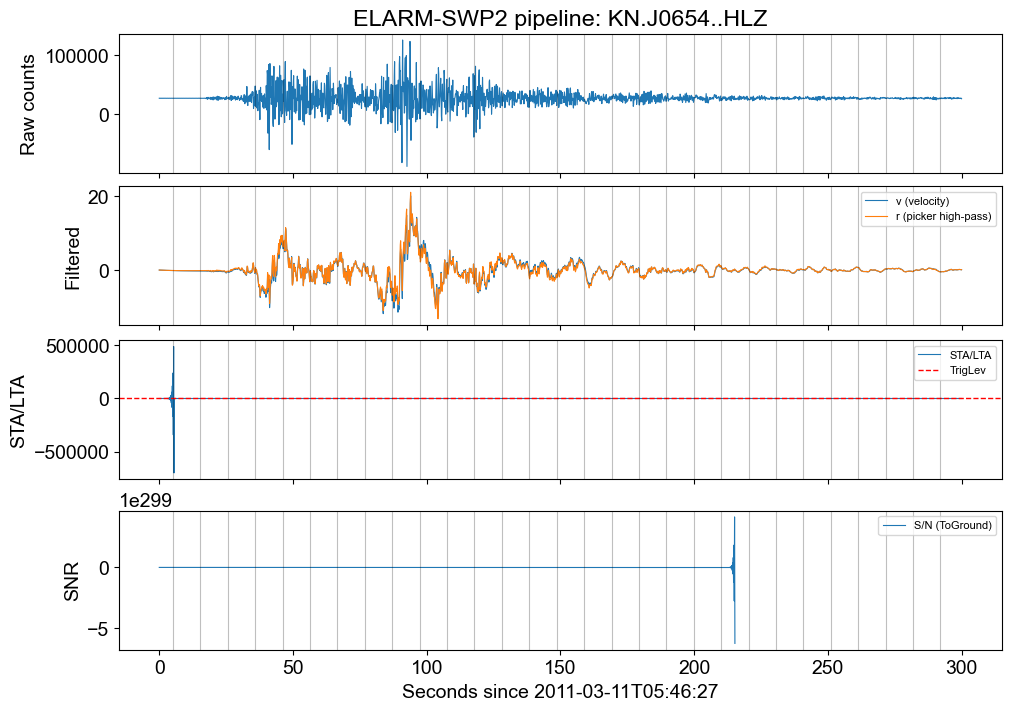

In [17]:
fig, axs = plt.subplots(4, 1, figsize=(10, 7), sharex=True, constrained_layout=True)

axs[0].plot(trel, z_proc["raw"], lw=0.8)
axs[0].set_ylabel("Raw counts")
axs[0].set_title(f"ELARM-SWP2 pipeline: {z_proc['id']}")


axs[1].plot(trel, z_proc["v"], lw=0.8, label="v (velocity)")
axs[1].plot(trel, z_proc["r_picker"], lw=0.8, label="r (picker high-pass)")
axs[1].set_ylabel("Filtered")
axs[1].legend(loc="upper right", fontsize=8)


axs[2].plot(trel, z_proc["ratio"], lw=0.8, label="STA/LTA")
axs[2].axhline(float(params["TrigLev"]), color="r", ls="--", lw=1.0, label="TrigLev")
axs[2].set_ylabel("STA/LTA")
axs[2].legend(loc="upper right", fontsize=8)
# axs[2].set_ylim(-10,10)

axs[3].plot(trel, z_proc["snr"], lw=0.8, label="S/N (ToGround)")
axs[3].set_ylabel("SNR")
axs[3].set_xlabel(f"Seconds since {zst.stats.starttime.isoformat()}")
axs[3].legend(loc="upper right", fontsize=8)


trigger_events = z_proc["trigger_events"]
for ev in trigger_events:
    x = ev.sample_time_epoch - t0
    for ax in axs:
        ax.axvline(x, color="k", alpha=0.25, lw=0.8)

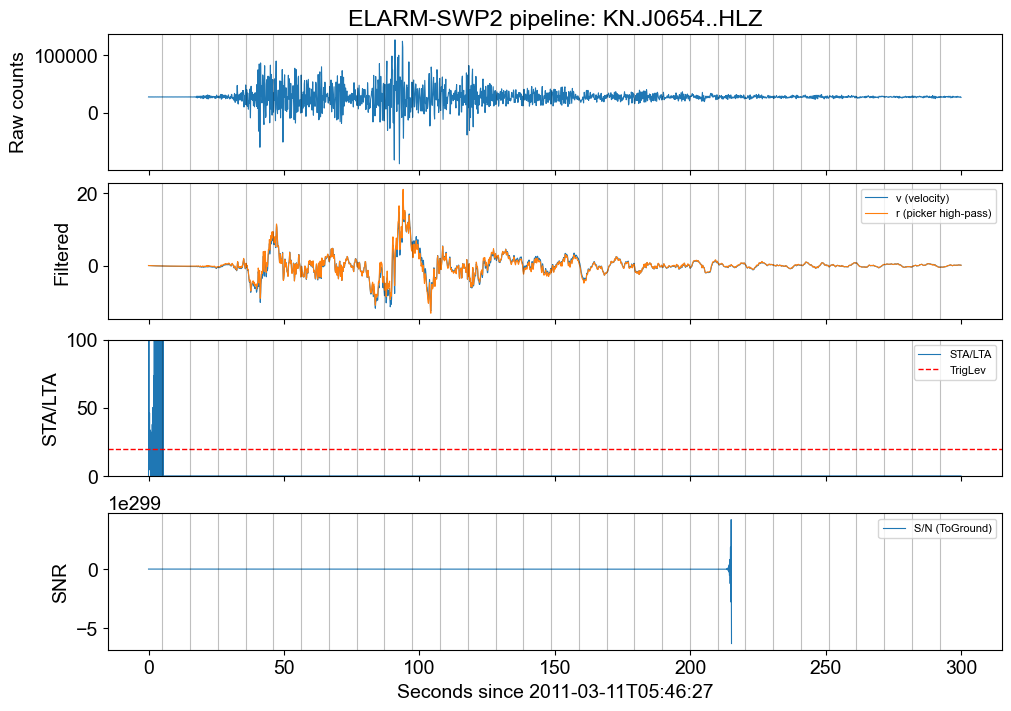

In [18]:
fig, axs = plt.subplots(4, 1, figsize=(10, 7), sharex=True, constrained_layout=True)

axs[0].plot(trel, z_proc["raw"], lw=0.8)
axs[0].set_ylabel("Raw counts")
axs[0].set_title(f"ELARM-SWP2 pipeline: {z_proc['id']}")


axs[1].plot(trel, z_proc["v"], lw=0.8, label="v (velocity)")
axs[1].plot(trel, z_proc["r_picker"], lw=0.8, label="r (picker high-pass)")
axs[1].set_ylabel("Filtered")
axs[1].legend(loc="upper right", fontsize=8)


axs[2].plot(trel, z_proc["ratio"], lw=0.8, label="STA/LTA")
axs[2].axhline(float(params["TrigLev"]), color="r", ls="--", lw=1.0, label="TrigLev")
axs[2].set_ylabel("STA/LTA")
axs[2].legend(loc="upper right", fontsize=8)
axs[2].set_ylim(0,100)

axs[3].plot(trel, z_proc["snr"], lw=0.8, label="S/N (ToGround)")
axs[3].set_ylabel("SNR")
axs[3].set_xlabel(f"Seconds since {zst.stats.starttime.isoformat()}")
axs[3].legend(loc="upper right", fontsize=8)


trigger_events = z_proc["trigger_events"]
for ev in trigger_events:
    x = ev.sample_time_epoch - t0
    for ax in axs:
        ax.axvline(x, color="k", alpha=0.25, lw=0.8)

## Starting over - starting with STA/LTA

In [19]:
DEFAULTS = {
    # ToGround
    "HPFCAcceleration": 0.994,
    "HPFCVelocityA": 0.994,
    "HPFCVelocityV": 0.994,
    # Picker
    "HPFCRaw": 0.994,
    "TSCTsta": 0.05,
    "TSCTlta": 5.0,
    "RICTauK": 3.0,
    "TrigLev": 20.0,
    "TrigDur": 10,
    "UseTrigStab": False,
    "TrigStabLev": 12.0,
    "UseTrigGapDelay": True,
    "TrigGapDur": 5,
}

In [20]:
# Convert input time series to velocity/acceleration; implement gain correction

def toground_velocity(raw: np.ndarray, fs: float, gain: float, channel: str, p: dict[str, float]) -> np.ndarray:
    """Return v[] as EWP2 ToGround does (minimal implementation)."""
    dt = 1.0 / fs
    q_acc = p["HPFCAcceleration"]
    q_vel_a = p["HPFCVelocityA"]
    q_vel_v = p["HPFCVelocityV"]

    bg_for_accel = 2.0 * gain / (1.0 + q_acc)
    tg_for_accel = dt * gain
    t2b_for_velo = (1.0 + q_vel_a) * dt / 4.0
    bg_for_velo = 2.0 * gain / (1.0 + q_vel_v)

    n = raw.size
    a = np.zeros(n, dtype=np.float64)
    v = np.zeros(n, dtype=np.float64)

    acceleration_input = len(channel) > 1 and channel[1] in {"N", "L"}

    # initial state equivalent
    var_z0 = raw[0]
    var_a0 = 0.0
    var_v0 = 0.0

    # i=0
    if acceleration_input:
        a[0] = (raw[0] - var_z0) / bg_for_accel + q_acc * var_a0
        v[0] = (a[0] + var_a0) * t2b_for_velo + q_vel_a * var_v0
    else:
        a[0] = (raw[0] - var_z0) / tg_for_accel
        v[0] = (raw[0] - var_z0) / bg_for_velo + q_vel_v * var_v0

    # i>=1
    for i in range(1, n):
        dz = raw[i] - raw[i - 1]
        if acceleration_input:
            a[i] = dz / bg_for_accel + q_acc * a[i - 1]
            v[i] = (a[i] + a[i - 1]) * t2b_for_velo + q_vel_a * v[i - 1]
        else:
            a[i] = dz / tg_for_accel
            v[i] = dz / bg_for_velo + q_vel_v * v[i - 1]

    return v

In [21]:
def picker_sta_lta_and_triggers(
    v: np.ndarray,
    fs: float,
    first_sample_time: float,
    p: dict[str, float | int | bool],
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Compute picker high-pass r, STA, LTA, ratio, and trigger times.

    Trigger condition follows PickerTSPModule behavior:
      stabilized && gap-delay-passed && untrigger-window-passed && sta > TrigLev * lta
    """
    dt = 1.0 / fs

    # Picker parameters
    q_raw = float(p["HPFCRaw"])
    t_sta = float(p["TSCTsta"])
    t_lta = float(p["TSCTlta"])
    tau_k = float(p["RICTauK"])

    trig_lev = float(p["TrigLev"])
    trig_dur = float(p["TrigDur"])
    use_trig_stab = bool(p["UseTrigStab"])
    trig_stab_lev = float(p["TrigStabLev"])
    use_trig_gap_delay = bool(p["UseTrigGapDelay"])
    trig_gap_dur = float(p["TrigGapDur"])

    # Exponential smoothing coefficients for STA/LTA updates
    a1_sta = dt / t_sta
    a1_lta = dt / t_lta
    a_sta = 1.0 - a1_sta
    a_lta = 1.0 - a1_lta

    n = v.size
    r = np.zeros(n, dtype=np.float64)
    sta = np.zeros(n, dtype=np.float64)
    lta = np.zeros(n, dtype=np.float64)

    # Saved state (equivalent to "prev_*" values in C++)
    prev_v = 0.0
    prev_r = 0.0
    prev_sta = 0.0
    prev_lta = 0.0

    # Gap behavior at start of process() call
    in_gap = True
    time_gap_delay = 0.0
    if in_gap:
        in_gap = False
        time_gap_delay = first_sample_time + abs(trig_gap_dur)

    # Stabilization is either required (false initially) or disabled (true initially)
    stabilized = not use_trig_stab

    # Holdoff after a trigger to prevent immediate retriggering
    time_untrig = 0.0

    trig_idx: list[int] = []
    trig_time: list[float] = []

    # ----- i = 0 -----
    r[0] = q_raw * prev_r + (v[0] - prev_v)
    cf0 = r[0] ** 2 + tau_k * (v[0] - prev_v) ** 2
    sta[0] = a_sta * prev_sta + a1_sta * cf0
    lta[0] = a_lta * prev_lta + a1_lta * cf0

    # Once stabilized condition is met once, it remains true
    if sta[0] < trig_stab_lev * lta[0]:
        stabilized = True

    t0 = first_sample_time
    if (
        stabilized
        and ((not use_trig_gap_delay) or (t0 > time_gap_delay))
        and t0 > time_untrig
        and sta[0] > trig_lev * lta[0]
    ):
        trig_idx.append(0)
        trig_time.append(t0)
        time_untrig = t0 + trig_dur

    # ----- i >= 1 -----
    for i in range(1, n):
        sample_time = first_sample_time + i * dt
        dv = v[i] - v[i - 1]

        # Picker high-pass of velocity
        r[i] = q_raw * r[i - 1] + dv

        # Characteristic function used for STA/LTA
        cfi = r[i] ** 2 + tau_k * dv ** 2
        sta[i] = a_sta * sta[i - 1] + a1_sta * cfi
        lta[i] = a_lta * lta[i - 1] + a1_lta * cfi

        if sta[i] < trig_stab_lev * lta[i]:
            stabilized = True

        if (
            stabilized
            and ((not use_trig_gap_delay) or (sample_time > time_gap_delay))
            and sample_time > time_untrig
            and sta[i] > trig_lev * lta[i]
        ):
            trig_idx.append(i)
            trig_time.append(sample_time)
            time_untrig = sample_time + trig_dur

    # Ratio is useful for plotting; picker itself uses sta/lta comparison directly
    ratio = np.divide(sta, lta, out=np.zeros_like(sta), where=lta != 0.0)

    return (
        r,
        sta,
        lta,
        ratio,
        np.array(trig_idx, dtype=int),
        np.array(trig_time, dtype=np.float64),
    )

In [22]:
mseed_path_z = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KN.J0654.HLZ.mseed'
gain  = 1577.23494898

In [23]:
DEFAULTS = {
    # ToGround
    "HPFCAcceleration": 0.994,
    "HPFCVelocityA": 0.994,
    "HPFCVelocityV": 0.994,
    # Picker
    "HPFCRaw": 0.994,
    "TSCTsta": 0.05,
    "TSCTlta": 5.0,
    "RICTauK": 3.0,
    "TrigLev": 20.0,
    "TrigDur": 10,
    "UseTrigStab": False,
    "TrigStabLev": 12.0,
    "UseTrigGapDelay": True,
    "TrigGapDur": 5,
}

p = dict(DEFAULTS)

st = read(mseed_path_z)
tr1 = st[0]

# Extract core inputs for the recursions
raw = tr1.data.astype(np.float64)
fs = float(tr1.stats.sampling_rate)
ch = str(getattr(tr1.stats, "channel", ""))
first_sample_time = float(tr1.stats.starttime.timestamp)

# Pipeline:
#   raw counts -> velocity (ToGround) -> picker STA/LTA + triggers
v1 = toground_velocity(raw, fs, gain, ch, p)
r1, sta1, lta1, ratio1, trig_idx1, trig_time1 = picker_sta_lta_and_triggers(v1, fs, first_sample_time, p)


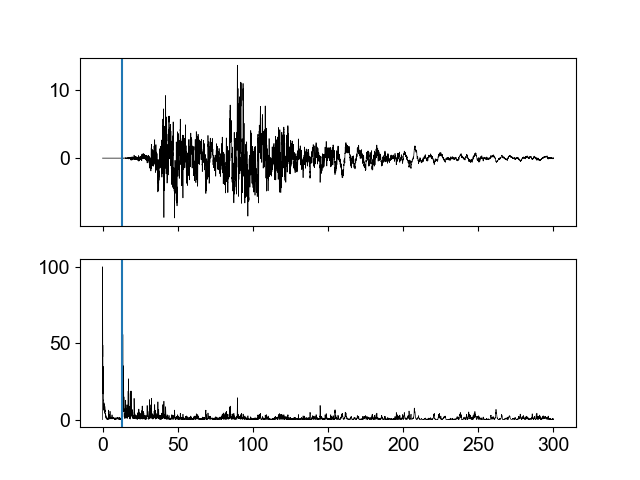

In [24]:
%matplotlib widget

fig,ax = plt.subplots(2,sharex=True)
ax[0].plot(tr1.times(),v1,'k-',linewidth = 0.5)
# ax[0].plot(tr.times(),raw,'k-',linewidth = 0.5)
ax[1].plot(tr1.times(),ratio1,'k-',linewidth = 0.5)

ax[0].axvline(tr1.times()[trig_idx1[0]])
ax[1].axvline(tr1.times()[trig_idx1[0]])

# ax[0].set_xlim(12,20)

## Now do downsampled

In [25]:
DEFAULTS = {
    # ToGround
    "HPFCAcceleration": 0.994,
    "HPFCVelocityA": 0.994,
    "HPFCVelocityV": 0.994,
    # Picker
    "HPFCRaw": 0.994,
    "TSCTsta": 0.2, # default is 0.05
    "TSCTlta": 20.0,# default is 5.0
    "RICTauK": 3.0,
    "TrigLev": 20.0, # default is 20
    "TrigDur": 10,
    "UseTrigStab": False,
    "TrigStabLev": 12.0,
    "UseTrigGapDelay": True,
    "TrigGapDur": 5,
}

In [26]:
mseed_path_z = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/first10_downsampled_japan_mseeds/downsampled_japan.KN.J0654.HLZ.mseed'
gain  = 1577.23494898

In [27]:
p = dict(DEFAULTS)

st = read(mseed_path_z)
tr2 = st[0]

# Extract core inputs for the recursions
raw = tr2.data.astype(np.float64)
fs = float(tr2.stats.sampling_rate)
ch = str(getattr(tr2.stats, "channel", ""))
first_sample_time = float(tr2.stats.starttime.timestamp)

# Pipeline:
#   raw counts -> velocity (ToGround) -> picker STA/LTA + triggers
v2 = toground_velocity(raw, fs, gain, ch, p)
r2, sta2, lta2, ratio2, trig_idx2, trig_time2 = picker_sta_lta_and_triggers(v2, fs, first_sample_time, p)


In [28]:
# High pass filter above 1 Hz
tr2.data = tr2.data / gain
b,a = scipy.signal.butter(N=4, Wn=1, btype='highpass',fs=tr2.stats.sampling_rate)
ds_filtered = scipy.signal.filtfilt(b,a,tr2.data)

tr1.data = tr1.data / gain
b,a = scipy.signal.butter(N=4, Wn=1, btype='highpass',fs=tr1.stats.sampling_rate)
fullrate_filtered = scipy.signal.filtfilt(b,a,tr1.data)

Text(0.5, 0, 'Time (s)')

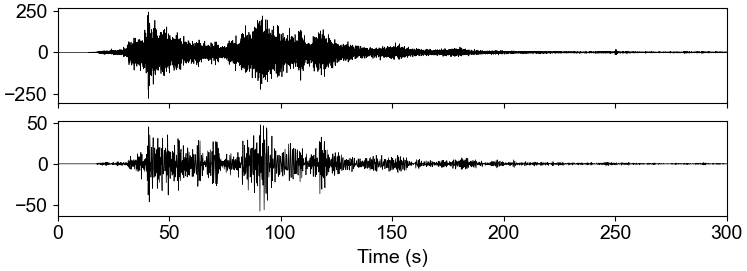

In [29]:
%matplotlib widget

fig,ax = plt.subplots(2,sharex=True,figsize=[7.47, 2.71],constrained_layout=True)
ax[0].plot(tr1.times(),fullrate_filtered,'k-',linewidth = 0.5)
ax[1].plot(tr2.times(),ds_filtered,'k-',linewidth = 0.5)

ax[1].set_xlim(0,300)
ax[1].set_xlabel('Time (s)')

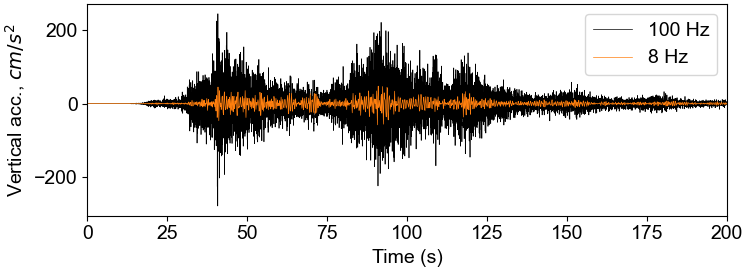

In [30]:
%matplotlib widget

fig,ax = plt.subplots(1,sharex=True,figsize=[7.47, 2.71],constrained_layout=True)
ax.plot(tr1.times(),fullrate_filtered,'k-',linewidth = 0.5,label='100 Hz')
ax.plot(tr2.times(),ds_filtered,'-',color='tab:orange',linewidth = 0.5,label='8 Hz')

ax.set_ylabel('Vertical acc., $cm/s^2$')
ax.set_xlim(0,200)
ax.set_xlabel('Time (s)')
ax.legend(loc='upper right')

fig.patch.set_facecolor('none')  # Makes the outer figure background transparent
ax.patch.set_facecolor('white')  # Keeps the inner axes background solid white


plt.savefig('/Users/zoekrauss/shakealert_8hz/kona_figs/japan_big_waveform.png', dpi=300)

In [31]:
plt.gcf().get_size_inches()

array([7.47, 2.71])

/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12608/992269959.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  ax[1].plot(tr1.times(),ratio1,'k-',linewidth = 1,color='tab:orange')


Text(0, 0.5, 'STA/LTA')

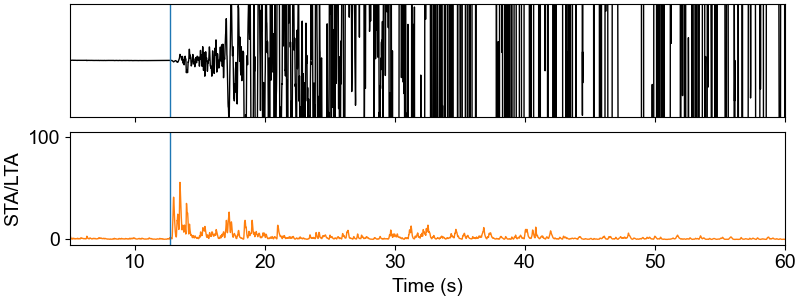

In [32]:
%matplotlib widget

fig,ax = plt.subplots(2,sharex=True,figsize=[8,3],constrained_layout=True)
ax[0].plot(tr1.times(),v1,'k-',linewidth = 1)
ax[1].plot(tr1.times(),ratio1,'k-',linewidth = 1,color='tab:orange')

ax[1].set_xlim(5,60)
ax[1].set_xlabel('Time (s)')
ax[0].set_ylim(-0.1,0.1)

ax[0].axvline(12.7,linewidth=1)
ax[1].axvline(12.7,linewidth=1)

ax[0].set_yticks([])

ax[1].set_ylabel('STA/LTA')


/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12608/3974396386.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  ax[1].plot(tr2.times(),ratio2,'k-',linewidth = 1,color='tab:orange')


Text(0, 0.5, 'STA/LTA')

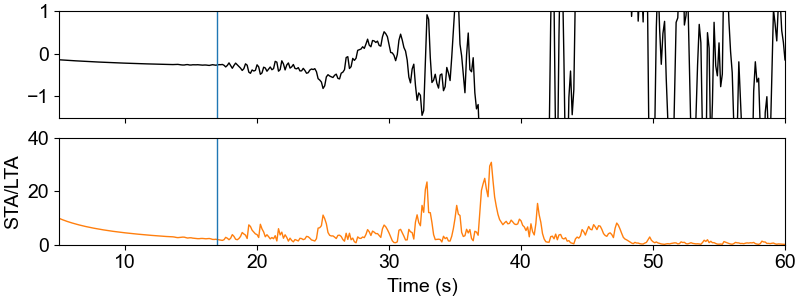

In [33]:
%matplotlib widget

fig,ax = plt.subplots(2,sharex=True,figsize=[8,3],constrained_layout=True)
ax[0].plot(tr2.times(),v2,'k-',linewidth = 1)
ax[1].plot(tr2.times(),ratio2,'k-',linewidth = 1,color='tab:orange')

ax[1].set_xlim(5,60)
ax[1].set_ylim(0,40)
ax[1].set_xlabel('Time (s)')
ax[0].set_ylim(-1.5,1)

ax[0].axvline(17,linewidth=1)
ax[1].axvline(17,linewidth=1)

ax[1].set_ylabel('STA/LTA')

/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12608/624276464.py:3: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  ax[1].plot(tr1.times(),ratio1,'k-',linewidth = 1,color='tab:orange')
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12608/624276464.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  ax[3].plot(tr2.times(),ratio2,'k-',linewidth = 1,color='tab:orange')


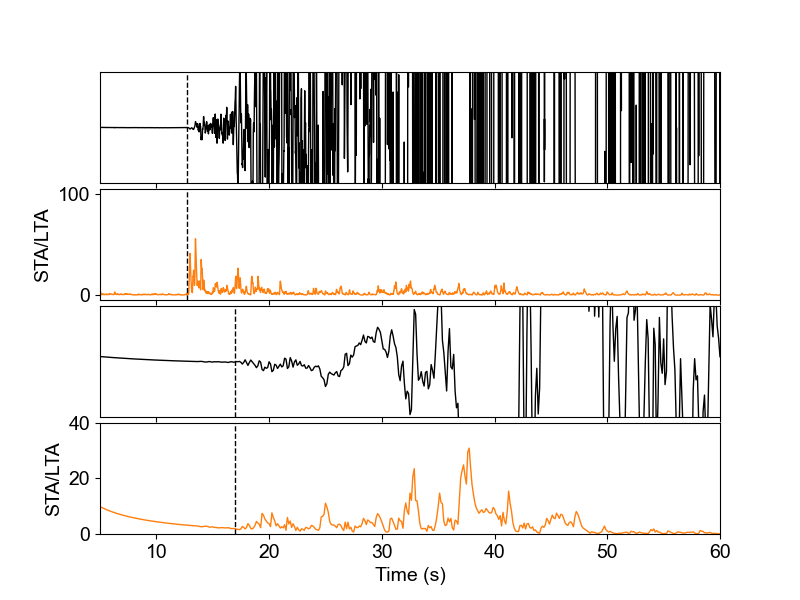

In [34]:
fig,ax = plt.subplots(4,sharex=True,figsize=[8,6])
ax[0].plot(tr1.times(),v1,'k-',linewidth = 1)
ax[1].plot(tr1.times(),ratio1,'k-',linewidth = 1,color='tab:orange')
ax[2].plot(tr2.times(),v2,'k-',linewidth = 1)
ax[3].plot(tr2.times(),ratio2,'k-',linewidth = 1,color='tab:orange')

ax[1].set_xlim(5,60)
ax[0].set_ylim(-0.1,0.1)
ax[0].axvline(12.7,linewidth=1,color='k',linestyle='--')
ax[1].axvline(12.7,linewidth=1,color='k',linestyle='--')

ax[3].set_ylim(0,40)
ax[3].set_xlabel('Time (s)')
ax[2].set_ylim(-1.5,1)
ax[2].axvline(17,linewidth=1,color='k',linestyle='--')
ax[3].axvline(17,linewidth=1,color='k',linestyle='--')

ax[0].set_yticks([])
ax[2].set_yticks([])

ax[1].set_ylabel('STA/LTA')
ax[3].set_ylabel('STA/LTA')


fig.patch.set_facecolor('none')  # Makes the outer figure background transparent
ax[0].patch.set_facecolor('white')  # Keeps the inner axes background solid white
ax[1].patch.set_facecolor('white')  # Keeps the inner axes background solid white
ax[2].patch.set_facecolor('white')  # Keeps the inner axes background solid white
ax[3].patch.set_facecolor('white')  # Keeps the inner axes background solid white

plt.subplots_adjust(hspace=0.05) 
plt.savefig('/Users/zoekrauss/shakealert_8hz/kona_figs/japan_stalta.png', dpi=300)

In [35]:
plt.gcf().get_size_inches()

array([8., 6.])